# Heart Disease Triage: Prioritising the Angiography Queue with Machine Learning
### A data science report on the UCI Cleveland Heart Disease dataset

> **Executive summary.** Cardiovascular disease is the world's leading cause of death, and confirmatory coronary angiography is invasive and poorly targeted: in a US registry of 398,978 elective angiograms only 37.6% found obstructive disease (Section 0), so deciding *who goes first* matters. This report builds a model that, for a patient with history, ECG and the recorded exercise-test measures available before angiography, estimates the probability that angiography will show significant coronary narrowing, and turns it into a three-tier triage recommendation. The model is **recall-first**: missing a sick patient is the error we minimise. Before any modelling we audited the data and found that the widely used Kaggle copy of this dataset has **inverted labels, scrambled category codes, and one lost patient**, so every result here comes from the original UCI file.

> **The problem in one line.**
> **Who:** a cardiologist ordering the angiography queue. **When:** after the initial work-up (history, ECG, recorded stress-test measures). **Predicts:** the probability that angiography will show more than 50% narrowing in a major vessel. **Action:** High risk → priority angiography; Medium → cardiology review or further testing; Low → clinician review with a documented safety-net plan. **Success:** flag at least 90% of sick patients (recall ≥ 0.90), assessed with independent threshold-selection folds (Section 13); the locked test result in Section 11 applies to the retrospective 13-feature model.

**How to read this notebook.** All logic lives in the `cardiotriage` Python package (see `STRUCTURE.md`); each cell here is a short call into it, followed by what we learned. Every analysis cell is preceded by its purpose and followed by an **Insight** that quotes a number printed by that cell.

## 0. Why this matters

**Layer 1: heart disease is common, deadly and expensive.**

| Fact | Figure | Source |
|---|---|---|
| Deaths from cardiovascular disease (CVD) worldwide, 2022 | about **19.8 million**, roughly 32% of all deaths; 85% of them from heart attack and stroke | WHO CVD fact sheet, updated 31 July 2025 |
| CVD deaths in the United States, 2023 | **919,032**, about 1 in 3 deaths, one every ~34 seconds | CDC, Heart Disease Facts |
| Cost of heart disease in the United States, 2021–2022 | more than **$168 billion** in health care services and medications | CDC, Heart Disease Facts |

**Layer 2: the angiography queue is where better ranking pays off.**

| Fact | Figure | Source |
|---|---|---|
| Most elective angiograms find no obstructive disease (US, 2004–2008) | of **398,978** patients without known coronary disease sent for elective catheterisation, only **149,739 (37.6%)** had obstructive disease and **39.2%** had none; a positive non-invasive test raised the yield only to 41.0% (vs 35.0% with no test) | Patel et al., *N Engl J Med* 2010;362:886–95 |
| Angiography is safe but not harmless (Mayo Clinic, 2002–2013) | major complications within 72 hours (death, heart attack, stroke, tamponade, dissection, emergency bypass) in **36 of 43,786** diagnostic catheterisations, **8.2 per 10,000** | Al-Hijji et al., *Circ Cardiovasc Interv* 2019;12:e007791 |
| Missing a sick patient is the costly error (10 US hospitals, published 2000) | **19 of 889** patients with acute myocardial infarction (2.1%, 95% CI 1.1–3.1%) were mistakenly sent home; among all acute cardiac ischaemia, women under 55 had 6.7 times the odds of being sent home (95% CI 1.4–32.5) | Pope et al., *N Engl J Med* 2000;342:1163–70 |
| Waiting for the angiogram is itself dangerous (Hamilton, Ontario, 1998–2000) | of **8,030** consecutive patients referred for catheterisation, **109 (1.4%)** died, had a heart attack or developed heart failure while on the waiting list (50 deaths); the median wait was 60 days for outpatients, and only **37%** of procedures were done within the wait the referring physician asked for | Natarajan et al., *CMAJ* 2002;167:1233–40 |
| Waiting still harms patients today (Ontario, referrals 2014–2020) | of **584,341** first-time referrals for coronary or valve procedures, patients referred for **PCI during the COVID-19 pandemic**, when queues were disrupted, had higher all-cause mortality while waiting (hazard ratio **1.83**, 95% CI 1.47–2.27; for bypass surgery **1.96**, 1.28–3.01) | Tam et al., *Can J Cardiol* 2021;37:1547–54 |
| The queues are still long (England, end of September 2025) | **397,478** people waiting for routine cardiac care, **148,882** of them (37%) for 18 weeks or more | British Heart Foundation analysis of NHS England data, 13 November 2025 |
| What one diagnostic angiogram costs (US Medicare, calendar year 2026) | **$3,312** national hospital-outpatient payment for coronary angiography with left-heart catheterisation (CPT 93458, APC 5191), or **$1,708** in an ambulatory surgical centre; the physician's fee is extra | CMS CY 2026 OPPS/ASC final rule CMS-1834-FC (published 21 November 2025), national unadjusted rates as tabulated in Medtronic's 2026 Coronary Reimbursement Guide |

**Layer 3: the same pressure in Thailand.**

| Fact | Figure | Source |
|---|---|---|
| Heart-attack deaths are rising, fastest in younger adults (Ministry of Public Health data, 2012–2021) | age-standardised ischaemic heart disease mortality went from **23.4 to 26.9 per 100,000**; under age 60 it rose by **59.6% in men** and **36.1% in women** | Sakboonyarat & Rangsin, *BMC Res Notes* 2024;17:142 |
| Access to angiography is linked to survival (Universal Coverage claims, first acute coronary syndrome, 2017) | patients who received angiography and PCI had lower 5-year mortality than propensity-matched patients who did not: hazard ratio **0.55** after STEMI and **0.57** after NSTE-ACS (observational) | Kumwichar et al., *Glob Health Res Policy* 2024;9:48 |
| Thai angiograms often lead to no treatment, nationally (Universal Coverage claims, fiscal years 2020–2023) | of **141,605** coronary angiograms, **53,300 patients (37.6%)** had the angiogram and nothing else: no stent and no bypass. This includes sick patients treated with medicines, so it is an upper bound on unneeded angiograms | Khananuraksa et al., *J Health Sci Thai* 2024;33(3):505–16 |
| One Thai hospital in detail (Chiangrai Prachanukroh Hospital, 2023) | **36.1%** of 122 non-urgent angiograms found normal coronary arteries | *Chiangrai Med J* 2025;17(2):1–10 |
| The volume is large (Universal Coverage, fiscal year 2025) | **65,744** patients had coronary diagnosis or treatment, including **33,667** angiograms with no further procedure | NHSO annual report FY2025, as reported by Thai PBS Policy Watch, 21 August 2026 |
| Capacity is thin (Thai PCI Registry, 2018–2019) | **72** hospitals able to do coronary intervention nationwide, about **1 per million people** (71.5 million people, World Bank 2019). For scale, ESC member countries have **5.7** cath labs per million (2023). A hospital can run several labs, so this is an order-of-magnitude contrast, not a like-for-like count | Chandavimol et al., *Catheter Cardiovasc Interv* 2025;105(2):442–55; World Bank; ESC Atlas of Cardiology |

**What this means for the model.** The disease is common and deadly, most angiography slots go to patients without obstructive disease, and the costliest mistake is the quiet one: a sick patient classified as low-risk. Waiting is not harmless either: in Ontario 1.4% of patients on the catheterisation list had a major cardiac event before their procedure, and the authors call for "prioritization schemes that allow earlier access for patients at higher risk". Two decades later the risk is still measurable: when the pandemic disrupted Ontario's queues, patients referred for PCI had 1.83 times the hazard of dying while they waited (Tam et al. 2021). The queues have not gone away: in England 148,882 people had waited 18 weeks or more for cardiac care at the end of September 2025. Patel and colleagues conclude that "better strategies for risk stratification are needed"; a model that ranks referred patients by risk is one such strategy. It lets clinicians send the highest-risk patients to angiography first without losing sick patients in the queue, so **recall (sensitivity) on the disease class is our primary metric**. The Thai figures show the same question is live here, at national scale: heart-attack mortality is rising, access to angiography is linked to survival, 37.6% of Universal Coverage angiograms led to no stent or bypass, and with about one intervention hospital per million people every slot counts. We state the benefit first in patients and angiography slots (Sections 10 and 15), then in money, using the 2026 US Medicare payment for a diagnostic angiogram (Section 15.2). We found no published Thai public price per diagnostic angiogram (we searched NHSO announcements and the Comptroller General's Department fee schedule) and no UK one, so the money figures are a US illustration, not a Thai budget. The number that does transfer is the count: angiograms avoided per 1,000 referred patients (Section 15.2), which any hospital can multiply by its own cost.

Sources: [WHO fact sheet](https://www.who.int/news-room/fact-sheets/detail/cardiovascular-diseases-(cvds)) · [CDC Heart Disease Facts](https://www.cdc.gov/heart-disease/data-research/facts-stats/) · [Patel et al. 2010 (PMID 20220183)](https://europepmc.org/article/MED/20220183) · [Al-Hijji et al. 2019](https://doi.org/10.1161/CIRCINTERVENTIONS.119.007791) · [Pope et al. 2000 (PMID 10770981)](https://europepmc.org/article/MED/10770981) · [Natarajan et al. 2002 (PMID 12451076)](https://europepmc.org/article/MED/12451076) · [Sakboonyarat & Rangsin 2024](https://doi.org/10.1186/s13104-024-06803-x) · [Kumwichar et al. 2024](https://doi.org/10.1186/s41256-024-00390-x) · [Tam et al. 2021 (PMID 34600793)](https://doi.org/10.1016/j.cjca.2021.05.008) · [Khananuraksa et al. 2024](https://thaidj.org/index.php/JHS/article/view/15212) · [Thai PBS Policy Watch, 21 Aug 2026](https://policywatch.thaipbs.or.th/article/life-365) · [Chandavimol et al. 2025](https://doi.org/10.1002/ccd.31334) · [World Bank population](https://data.worldbank.org/indicator/SP.POP.TOTL?locations=TH) · [ESC Atlas: cath labs per million](https://eatlas.escardio.org/Data/Cardiovascular-healthcare-delivery/Interventional-cardiology-infrastructure/ccr_totcath_1m_r-total-cath-labs-per-million-people) · [Chiangrai Med J 2025](https://he01.tci-thaijo.org/index.php/crmjournal/article/view/276594) · [BHF, 13 Nov 2025](https://www.bhf.org.uk/what-we-do/news-from-the-bhf/news-archive/2025/november/heart-care-waiting-list-at-two-year-low) · [CMS CY 2026 OPPS final rule CMS-1834-FC](https://www.cms.gov/medicare/payment/prospective-payment-systems/hospital-outpatient/regulations-notices/cms-1834-fc) · [Medtronic 2026 Coronary Reimbursement Guide](https://www.medtronic.com/content/dam/medtronic-wide/public/united-states/customer-support-services/reimbursement/coronary-pci-reimbursement-guide.pdf)

## 1. Objective and operational context

**Objective.** Given the 10 attributes retained for the pre-angiography decision, estimate the probability that coronary angiography will show more than 50% narrowing in at least one major vessel, and use it to place each patient in a triage tier. Target: **flag at least 90% of patients who truly have disease (recall ≥ 0.90)** while keeping as many healthy patients as possible out of the priority queue.

**Prediction task:** binary classification, P(`disease` = 1 | 10 pre-angiography attributes), where `disease` = 1 means more than 50% narrowing of at least one major coronary vessel on angiography (UCI `num > 0`).

**Who uses it, and when.** A cardiologist or chest-pain-unit physician who already has the work-up results (history, resting ECG, recorded exercise-test measures) and must decide the order of the angiography queue. The model is **decision support**: the clinician makes the call.

**Decision flow.**

```
available results (10 attributes) ──► data contract check ──► model ──► risk % ──► triage tier ──► action
```

| Tier | Rule | Recommended action |
|---|---|---|
| High | risk ≥ upper cut-off | Priority angiography |
| Medium | between the cut-offs | Cardiology review or further testing |
| Low | risk < lower cut-off (set so recall ≥ 0.90) | Clinician review and a documented safety-net plan |

The cut-offs are chosen later from out-of-fold predictions on the training data, never from the test set.

**The cost of each error.**

| Error | What happens to the patient | Cost |
|---|---|---|
| False negative: a sick patient placed in the low tier | Delayed angiography; risk of heart attack or death while waiting | **Severe**: the error we minimise |
| False positive: a healthy patient placed in the high tier | Takes an angiography slot; procedure risk and cost | **Moderate**: we accept some to protect recall |

So recall is the primary metric; specificity, ROC-AUC and the Brier score (calibration) are constraints. Accuracy is reported only as a secondary number, because on this data a model that always predicts "no disease" is already 54% accurate (shown in the class-balance check below).

**Why classical tabular models, not deep learning.** With 303 patients and 13 structured features, linear and tree-based models are the right tools: they match or beat neural networks on small tabular data, they are interpretable (a clinician can see *why* a patient scored high), they run in milliseconds, and their probabilities can be checked for calibration.

**Input timing.** `ca` records vessels coloured by fluoroscopy and may be obtained during the angiogram being prioritised. UCI has no measurement timestamps, so prior availability is unproven. `thal` is thallium imaging and its timing is also unrecorded. The main demo uses the existing 10-feature model, excluding `ca`, `thal` and `slope`. `slope` is exercise ECG, excluded for cross-hospital completeness rather than imaging timing. The 13-feature model is retrospective comparison only. See Sections 5.9 and 13.

| Model | Role | Evidence |
|---|---|---|
| Main 10-feature model | Pre-angiography demo | Cleveland cross-validated ROC-AUC 0.844; Hungary external ROC-AUC 0.877 |
| Retrospective 13-feature model | Comparison | cross-validated ROC-AUC 0.900; 28 of 28 sick test patients flagged |

A Low tier requires clinician review before any deferral, a documented follow-up date and responsible contact, plus instructions for urgent assessment if chest pain is new or worsens. Suspected acute coronary syndrome follows an urgent pathway regardless of score. This proposed safety process has not been clinically validated.

Neither model is an at-the-door screening tool for the general public (trap T15).

## 2. Environment and reproducibility

**Purpose:** fix every random seed in one place and record library versions, so a teammate re-running this notebook gets the same numbers. Exact versions are pinned in `requirements.txt`.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import platform
import random

import matplotlib
import numpy as np
import pandas as pd
import seaborn
import sklearn
import xgboost
from IPython.display import display

from cardiotriage import config as cfg, data, plots

random.seed(cfg.SEED)
np.random.seed(cfg.SEED)
os.environ["PYTHONHASHSEED"] = str(cfg.SEED)   # applies to subprocesses (e.g. parallel CV workers)
plots.set_style()
pd.set_option("display.precision", 3)

print(f"Seed: {cfg.SEED}")
print(f"Python       {platform.python_version()}")
for name, module in [("pandas", pd), ("numpy", np), ("scikit-learn", sklearn), ("xgboost", xgboost),
                     ("matplotlib", matplotlib), ("seaborn", seaborn)]:
    print(f"{name:<13}{module.__version__}")

Seed: 42
Python       3.13.5
pandas       3.1.1
numpy        2.4.6
scikit-learn 1.9.1
xgboost      3.2.0
matplotlib   3.11.2
seaborn      0.13.2


## 3. Acquire and inspect the data

### Data assumptions
* **Source of truth.** The Cleveland subset of the UCI Heart Disease dataset (Cleveland Clinic Foundation, donated to UCI in 1988, licence CC BY 4.0), file `processed.cleveland.data`. Citation: Janosi A, Steinbrunn W, Pfisterer M, Detrano R. *Heart Disease* [dataset]. UCI Machine Learning Repository, 1989. [doi:10.24432/C52P4X](https://doi.org/10.24432/C52P4X).
* **Label.** `num` is the angiographic diagnosis (0 = less than 50% narrowing, 1–4 = more than 50% narrowing). Following standard practice we binarise it: `disease = num > 0`.
* **Missing values.** UCI marks unknown values with `?`; we read them as missing (NaN) rather than guessing.
* **One row per patient.** There are no patient IDs, so we assume each row is a distinct patient and check for exact duplicates in Section 4.
* **Population.** These are patients already referred for angiography, not the general public, so disease is far more common here than in a screening setting (spectrum bias, trap T16).

**Purpose:** load the original UCI file and look at its shape and first rows.

In [2]:
df = data.load_cleveland()
print(f"{df.shape[0]} patients x {len(cfg.FEATURES)} features (+ num, disease)")
display(df.head())

303 patients x 13 features (+ num, disease)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,disease
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


**Insight:** the file loads as 303 patients with 13 clinical features, the raw diagnosis `num` (0–4) and our binary target `disease`. Categorical columns use the official UCI codes (for example `cp` runs 1–4 and `thal` uses 3/6/7), which the dictionary below translates.

### 3.1 Data dictionary

**Purpose:** document what each feature measures and its valid codes. The same code tables power the data-contract check (`data.validate`) and the demo app, so the documentation cannot drift from the code.

In [3]:
dictionary = data.dictionary()
display(dictionary)
print(f"{len(dictionary)} features by type: {dictionary['type'].value_counts().to_dict()}")

,meaning,type,codes
feature,,,
age,Age in years,numeric,valid range 18-100
trestbps,Resting blood pressure on admission (mm Hg),numeric,valid range 60-260
chol,Serum cholesterol (mg/dl),numeric,valid range 80-700
thalach,Maximum heart rate achieved on the exercise te...,numeric,valid range 50-250
oldpeak,ST depression induced by exercise relative to ...,numeric,valid range 0.0-10.0
ca,Major vessels (0-3) coloured by fluoroscopy,ordinal,0 = 0 vessels; 1 = 1 vessel; 2 = 2 vessels; 3 ...
cp,Chest pain type,nominal,1 = typical angina; 2 = atypical angina; 3 = n...
restecg,Resting ECG result,nominal,0 = normal; 1 = ST-T wave abnormality; 2 = lef...
slope,Slope of the peak-exercise ST segment,nominal,1 = upsloping; 2 = flat; 3 = downsloping


13 features by type: {'numeric': 5, 'nominal': 4, 'binary': 3, 'ordinal': 1}


**Insight:** of the 13 features, 5 are numeric, 1 is ordinal (`ca`), 4 are nominal codes whose numbers are only labels (`cp`, `restecg`, `slope`, `thal`) and 3 are binary. The nominal ones must be one-hot encoded before modelling; the original notebook fed them in as plain numbers (trap T9).

### 3.2 Provenance check: is the popular Kaggle copy the same data?

The original notebook trained on `heart-disease.csv` from Kaggle. Its data dictionary looked plausible, but several patterns contradicted cardiology (for example, women appeared to have *more* disease than men). To find out why, we match every Kaggle row back to a UCI patient using six continuous measurements (age, sex, resting blood pressure, cholesterol, maximum heart rate and ST depression), then compare the label and every categorical code.

**Purpose:** prove, row by row, how the Kaggle file differs from the original.

In [4]:
check = data.kaggle_vs_uci()
uci_counts = df[cfg.TARGET].value_counts().sort_index()
print(f"Kaggle rows: {check['n_kaggle']}; matched to a UCI patient: {check['n_matched']}")
print(f"UCI Cleveland:  no disease {uci_counts[0]}, disease {uci_counts[1]}")
print("\nKaggle `target` (rows) vs UCI `disease` (columns):")
display(check["crosstabs"]["target"])
print("Rows where the documented Kaggle->UCI recode does NOT reproduce the UCI value:")
print(check["mismatches"])
for col in cfg.KAGGLE_TO_UCI:
    print(f"\nKaggle `{col}` (rows) vs UCI `{col}` (columns; -1 = missing in UCI):")
    display(check["crosstabs"][col])
print(f"\nExact duplicate rows in Kaggle: {check['kaggle_duplicates']}")
print("UCI patients with no Kaggle row:")
display(check["uci_unmatched"])

Kaggle rows: 303; matched to a UCI patient: 303
UCI Cleveland:  no disease 164, disease 139

Kaggle `target` (rows) vs UCI `disease` (columns):


disease,0,1
target,,
0,0,138
1,165,0


Rows where the documented Kaggle->UCI recode does NOT reproduce the UCI value:
{'target': 0, 'cp': 0, 'restecg': 0, 'slope': 0, 'thal': 0, 'ca': 0}

Kaggle `cp` (rows) vs UCI `cp` (columns; -1 = missing in UCI):


cp_uci,1.0,2.0,3.0,4.0
cp_kaggle,,,,
0,0,0,0,143
1,0,50,0,0
2,0,0,87,0
3,23,0,0,0



Kaggle `restecg` (rows) vs UCI `restecg` (columns; -1 = missing in UCI):


restecg_uci,0.0,1.0,2.0
restecg_kaggle,,,
0,0,0,147
1,152,0,0
2,0,4,0


... (4 outputs left out)


Kaggle `ca` (rows) vs UCI `ca` (columns; -1 = missing in UCI):


ca_uci,-1.0,0.0,1.0,2.0,3.0
ca_kaggle,,,,,
0,0,175,0,0,0
1,0,0,65,0,0
2,0,0,0,38,0
3,0,0,0,0,20
4,5,0,0,0,0



Exact duplicate rows in Kaggle: 1
UCI patients with no Kaggle row:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,disease
184,60.0,0.0,4.0,158.0,305.0,0.0,2.0,161.0,0.0,0.0,1.0,0.0,3.0,1,1


**Insight:** all 303 Kaggle rows match a UCI patient, and the label is **inverted for every one of them**: the 165 rows Kaggle labels `target = 1` all have no disease, and the 138 rows labelled `target = 0` all have disease. Four categorical columns are also re-coded (`cp`, `restecg`, `slope`, `thal`), and Kaggle turns the UCI missing values into the fake codes `ca = 4` and `thal = 0`. Once the documented recode map is applied there are 0 mismatches in every column. Finally, Kaggle has 1 exact duplicate and is missing UCI patient 184, a patient *with* disease replaced by a copy of a healthy one, which is why Kaggle counts differ from UCI's 164 without and 139 with disease.

**Consequence.** Every clinical conclusion in the original notebook was read backwards, and its data dictionary described codes the file did not use (traps T1–T4). From here on we use only the UCI file, with the official codes.

## 4. Integrity QA and cleaning

### 4.1 Missing values (trap T3)

**Purpose:** count missing values per feature and see which patients they belong to.

In [5]:
missing = df[cfg.FEATURES].isna().sum()
print(f"Missing values: {int(missing.sum())} of {df[cfg.FEATURES].size} cells")
print(missing[missing > 0].to_string())
rows = df[df[cfg.FEATURES].isna().any(axis=1)]
print(f"\nPatients with any missing value: {len(rows)} ({len(rows) / len(df):.1%})")
display(rows[cfg.FEATURES + [cfg.TARGET]])

Missing values: 6 of 3939 cells
ca      4
thal    2

Patients with any missing value: 6 (2.0%)


,age,trestbps,chol,thalach,oldpeak,ca,cp,restecg,slope,thal,sex,fbs,exang,disease
87,53.0,128.0,216.0,115.0,0.0,0.0,3.0,2.0,1.0,NaN,0.0,0.0,0.0,0
166,52.0,138.0,223.0,169.0,0.0,NaN,3.0,0.0,1.0,3.0,1.0,0.0,0.0,0
192,43.0,132.0,247.0,143.0,0.1,NaN,4.0,2.0,2.0,7.0,1.0,1.0,1.0,1
266,52.0,128.0,204.0,156.0,1.0,0.0,4.0,0.0,2.0,NaN,1.0,1.0,1.0,1
287,58.0,125.0,220.0,144.0,0.4,NaN,2.0,0.0,2.0,7.0,1.0,0.0,0.0,0
302,38.0,138.0,175.0,173.0,0.0,NaN,3.0,0.0,1.0,3.0,1.0,0.0,0.0,0


**Insight:** only 6 of 3939 cells are missing: `ca` in 4 patients and `thal` in 2, spread over 6 patients (2.0%) of both classes.

**Rationale:** dropping those patients would throw away 2.0% of an already small dataset, so we keep them and **impute inside the model pipeline** (median for the ordinal `ca`, most frequent value for `thal`). Because imputation is fitted only on the training folds, no information leaks from validation or test data.

### 4.2 Duplicate patients (trap T4)

**Purpose:** check whether any patient appears twice, which would let the same person sit in both training and test data.

In [6]:
print(f"Exact duplicate rows in UCI Cleveland: {int(df.duplicated().sum())}")
print(f"Rows identical on all 13 features:      {int(df[cfg.FEATURES].duplicated().sum())}")

Exact duplicate rows in UCI Cleveland: 0
Rows identical on all 13 features:      0


**Insight:** the UCI file has 0 duplicate patients. The duplicate the original notebook carried came from the Kaggle copy, as shown above. We still run `data.deduplicate()` before splitting the data, as a guard.

### 4.3 Data contract and value ranges

**Purpose:** run the data contract (`data.validate`), which rejects missing columns, unknown category codes and physiologically impossible values, and inspect the actual ranges. As a negative control we also run it on the Kaggle file, which must fail.

In [7]:
data.validate(df)
print(f"UCI Cleveland: all {len(df)} patients pass the data contract")

ranges = df[cfg.NUMERIC].describe().T[["min", "50%", "max"]].rename(columns={"50%": "median"})
ranges["allowed range"] = [f"{lo}-{hi}" for lo, hi in (cfg.RANGES[c] for c in ranges.index)]
display(ranges)

try:
    data.validate(data.load_kaggle())
except ValueError as err:
    print("Kaggle file rejected, as expected:")
    print(str(err)[:300] + " ...")

UCI Cleveland: all 303 patients pass the data contract


,min,median,max,allowed range
age,29.0,56.0,77.0,18-100
trestbps,94.0,130.0,200.0,60-260
chol,126.0,241.0,564.0,80-700
thalach,71.0,153.0,202.0,50-250
oldpeak,0.0,0.8,6.2,0.0-10.0


Kaggle file rejected, as expected:
data contract violated: ca: 5 invalid code(s), e.g. 4; allowed [0, 1, 2, 3]; cp: 143 invalid code(s), e.g. 0; allowed [1, 2, 3, 4]; slope: 21 invalid code(s), e.g. 0; allowed [1, 2, 3]; thal: 186 invalid code(s), e.g. 1; allowed [3, 6, 7] ...


**Insight:** all 303 patients pass the contract. Observed ranges are clinically plausible: age 29–77 years, resting blood pressure 94–200 mm Hg, cholesterol 126–564 mg/dl, maximum heart rate 71–202 bpm and ST depression 0–6.2 mm. The extremes are rare but real values, so we do **no clipping or outlier removal**. The Kaggle file fails the contract on its non-UCI codes, so the check would have caught the problem automatically.

### 4.4 Class balance and the choice of metric

**Purpose:** measure the share of patients with disease and what a trivial model would score.

Disease: 139 of 303 (45.9%); no disease: 164 (54.1%)
'Always predict no disease' baseline: accuracy 54.1%, recall 0.0%


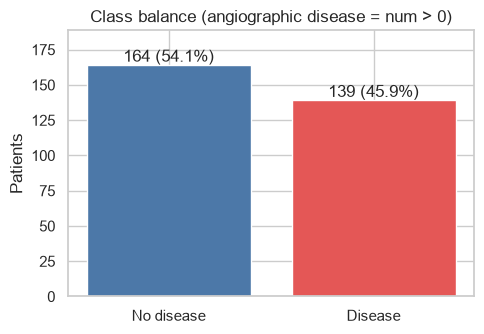

In [8]:
plots.class_balance(df);
n, n_pos = len(df), int(df[cfg.TARGET].sum())
print(f"Disease: {n_pos} of {n} ({n_pos / n:.1%}); no disease: {n - n_pos} ({(n - n_pos) / n:.1%})")
print(f"'Always predict no disease' baseline: accuracy {(n - n_pos) / n:.1%}, recall {0:.1%}")

**Insight:** 139 of 303 patients (45.9%) have disease, so the classes are only mildly imbalanced and **no resampling is needed**. A model that always predicts "no disease" would score 54.1% accuracy while catching 0.0% of sick patients, which is exactly why accuracy cannot be our headline metric.

### 4.5 Preprocessing decisions

| Issue | Decision | Rationale |
|---|---|---|
| Missing `ca`, `thal` | Impute inside the pipeline | Keeps all patients; fitted on training folds only, so no leakage |
| Nominal codes (`cp`, `restecg`, `slope`, `thal`) | One-hot encode | Their numbers are labels, not quantities (T9) |
| Numeric scale differences (cholesterol in the hundreds, ST depression 0–6) | Standardise inside the pipeline | Distance-based KNN and regularised logistic regression need comparable scales (T8); trees are unaffected |
| Outliers | Keep | All values are physiologically plausible |
| Class imbalance | No resampling | 46/54 split; we handle the error trade-off with the decision threshold instead |
| Duplicates | `deduplicate()` before splitting | 0 in UCI today; guards against future data |

## 5. Focused exploratory data analysis

We do not chart every column. Each block below tests one hypothesis that matters for the model or the clinical story, on the **corrected** UCI label. Rates are "share of patients with disease"; the dashed line on the bar charts is the overall rate of 46%.

### 5.1 Demographics: sex and age

**Hypothesis:** coronary disease is more common in men and in older patients.

,rate,with_disease,patients
sex,,,
female,25.8,25,97
male,55.3,114,206


Mean age by status: {'no disease': 52.6, 'disease': 56.6}


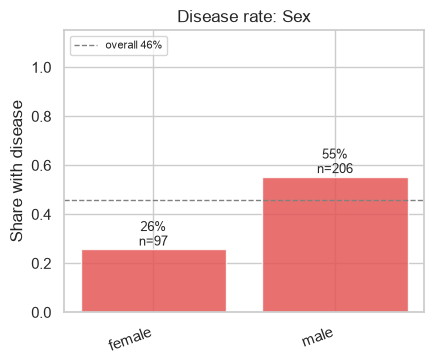

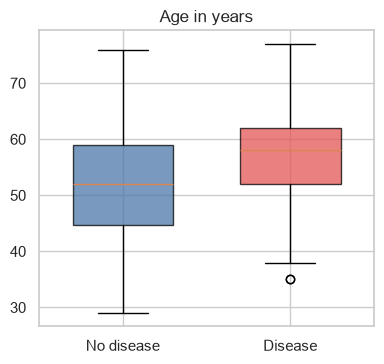

In [9]:
plots.rate_by(df, ["sex"]);
plots.by_disease(df, ["age"]);
by_sex = df.groupby("sex")[cfg.TARGET].agg(rate="mean", with_disease="sum", patients="size")
by_sex.index = by_sex.index.map(cfg.LABELS["sex"])
by_sex["rate"] = (by_sex["rate"] * 100).round(1)
display(by_sex)
print("Mean age by status:", df.groupby(cfg.TARGET)["age"].mean().round(1).rename({0: "no disease", 1: "disease"}).to_dict())

**Insight:** 55.3% of men have disease (114 of 206) against 25.8% of women (25 of 97), roughly twice the rate. Patients with disease are older on average (56.6 vs 52.6 years). With the inverted Kaggle label, the original notebook would have concluded the opposite about sex. Women are only 97 patients in total, and missed heart attacks are more common in women in practice, so we will check the model's recall for women separately.

### 5.2 Chest pain type

**Hypothesis:** textbook teaching says typical angina is the strongest symptom of coronary disease, so it should show the highest disease rate.

,rate,with_disease,patients
cp,,,
typical angina,30.4,7,23
atypical angina,18.0,9,50
non-anginal pain,20.9,18,86
asymptomatic,72.9,105,144


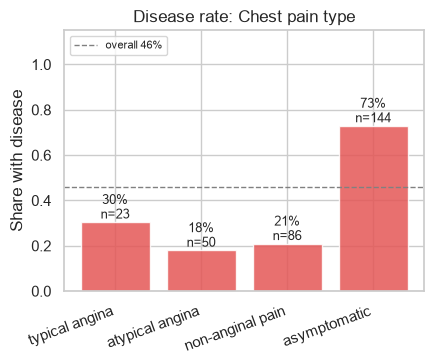

In [10]:
plots.rate_by(df, ["cp"]);
by_cp = df.groupby("cp")[cfg.TARGET].agg(rate="mean", with_disease="sum", patients="size")
by_cp.index = by_cp.index.map(cfg.LABELS["cp"])
by_cp["rate"] = (by_cp["rate"] * 100).round(1)
display(by_cp)

**Insight:** the hypothesis fails in this cohort. **Asymptomatic** patients have by far the highest rate, 72.9% (105 of 144), against 30.4% for typical angina, 18.0% for atypical angina and 20.9% for non-anginal pain. A likely explanation is selection: a patient without chest pain is only referred for angiography when another test was clearly abnormal. The model has to learn this cohort's pattern, which is one reason it should not be used outside this kind of referral setting.

### 5.3 Age and maximum heart rate

**Hypothesis:** a diseased heart cannot reach as high a heart rate on the exercise test, even after allowing for age (the age-predicted maximum is roughly 220 − age).

,mean max HR (bpm),mean % of age-predicted max,% below 85% of predicted max
disease,,,
no disease,158.4,94.6,15.9
disease,139.3,85.4,47.5


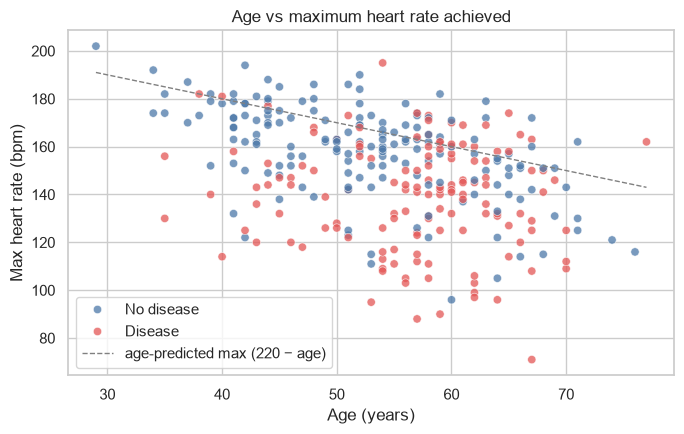

In [11]:
plots.age_vs_max_hr(df);
pct_max = df["thalach"] / (220 - df["age"])
summary = pd.DataFrame({
    "mean max HR (bpm)": df.groupby(cfg.TARGET)["thalach"].mean().round(1),
    "mean % of age-predicted max": (pct_max.groupby(df[cfg.TARGET]).mean() * 100).round(1),
    "% below 85% of predicted max": ((pct_max < 0.85).groupby(df[cfg.TARGET]).mean() * 100).round(1),
}).rename(index={0: "no disease", 1: "disease"})
display(summary)

**Insight:** patients with disease reach a lower peak heart rate (139.3 vs 158.4 bpm) and a lower share of their age-predicted maximum (85.4% vs 94.6%). 47.5% of them fail to reach 85% of the predicted maximum, against 15.9% of patients without disease. This supports adding "% of age-predicted maximum heart rate" as an engineered feature, which we test in the feature-engineering step.

### 5.4 Exercise stress test: angina, ST depression and ST slope

**Hypothesis:** signs of ischaemia during exercise (angina, ST-segment depression, a flat or downsloping ST segment) mark disease.

Disease rate (%) by exang: {'no exercise angina': 30.9, 'exercise angina': 76.8}
Disease rate (%) by slope: {'upsloping': 25.4, 'flat': 65.0, 'downsloping': 57.1}
ST depression (oldpeak) by status: {'no disease': {'mean': 0.59, 'over_1mm': 25.0}, 'disease': {'mean': 1.57, 'over_1mm': 59.0}}


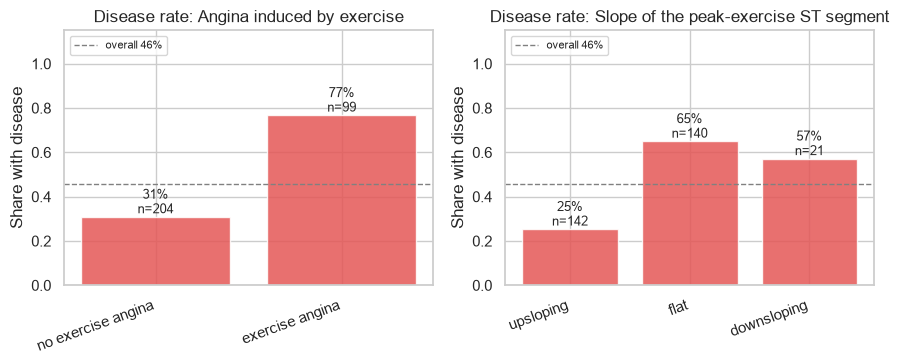

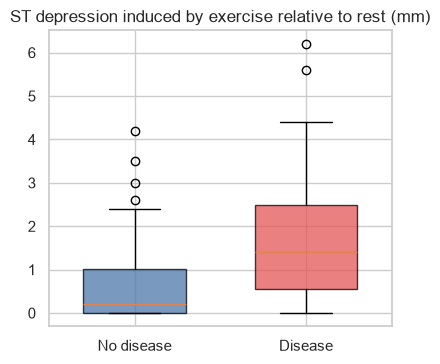

In [12]:
plots.rate_by(df, ["exang", "slope"]);
plots.by_disease(df, ["oldpeak"]);
for col in ["exang", "slope"]:
    rates = (df.groupby(col)[cfg.TARGET].mean() * 100).round(1)
    rates.index = rates.index.map(cfg.LABELS[col])
    print(f"Disease rate (%) by {col}: {rates.to_dict()}")
stats = df.groupby(cfg.TARGET)["oldpeak"].agg(mean="mean", over_1mm=lambda s: (s > 1).mean() * 100).round({"mean": 2, "over_1mm": 1})
print("ST depression (oldpeak) by status:", stats.rename(index={0: "no disease", 1: "disease"}).to_dict("index"))

**Insight:** exercise-induced angina raises the disease rate from 30.9% to 76.8%. Mean ST depression is 1.57 mm with disease against 0.59 mm without, and 59.0% of diseased patients exceed 1 mm against 25.0% of the others. A flat (65.0%) or downsloping (57.1%) ST segment is far more worrying than an upsloping one (25.4%). All three stress-test signals point the same way and match cardiology.

### 5.5 Imaging: vessels on fluoroscopy and the thallium scan

**Hypothesis:** more vessels coloured by fluoroscopy, and perfusion defects on the thallium scan, go with disease.

ca: 0 vessels 26.1% (n=176), 1 vessel 67.7% (n=65), 2 vessels 81.6% (n=38), 3 vessels 85.0% (n=20)
thal: normal 22.3% (n=166), fixed defect 66.7% (n=18), reversible defect 76.1% (n=117)


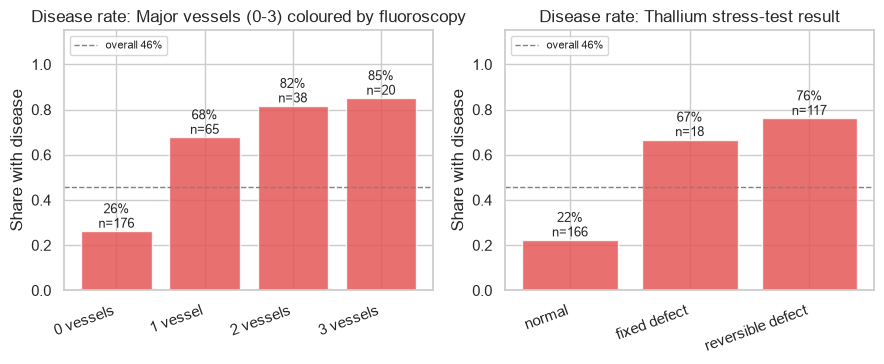

In [13]:
plots.rate_by(df, ["ca", "thal"]);
for col in ["ca", "thal"]:
    g = df.groupby(col)[cfg.TARGET].agg(["mean", "size"])
    print(f"{col}: " + ", ".join(f"{cfg.LABELS[col][int(c)]} {m * 100:.1f}% (n={int(n)})" for c, (m, n) in g.iterrows()))

**Insight:** the disease rate climbs steadily with the number of vessels seen, from 26.1% with 0 vessels to 85.0% with 3. A normal thallium scan goes with 22.3%, against 66.7% for a fixed defect and 76.1% for a reversible one. These are the strongest single signals, but they come from imaging late in the work-up, and `ca` is close to how the diagnosis itself is made. We keep them for the main, after-imaging model, and also build a model without the imaging results, so the work holds up before imaging is done (the two stages in the objective; trap T15).

### 5.6 How strong is each signal on its own?

**Hypothesis:** no single feature separates the two groups well, so we need a multivariable model.

Correlation with disease:
thalach    -0.42
fbs         0.03
chol        0.09
trestbps    0.15
age         0.22
sex         0.28
oldpeak     0.42
exang       0.43
ca          0.46


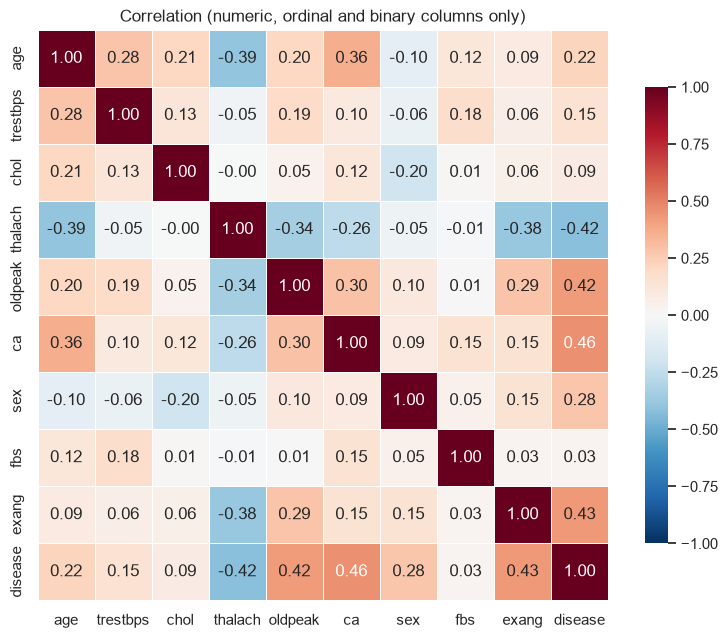

In [14]:
plots.correlation(df);
corr = df[cfg.NUMERIC + cfg.ORDINAL + cfg.BINARY].corrwith(df[cfg.TARGET]).round(2).sort_values()
print("Correlation with disease:\n" + corr.to_string())

**Insight:** the strongest single correlations with disease are moderate at best: `ca` 0.46, `exang` 0.43, `oldpeak` 0.42 and, negatively, maximum heart rate (`thalach`) −0.42. Cholesterol (0.09) and fasting blood sugar (0.03) are almost unrelated to the angiography result on their own. No feature comes close to separating the classes, so the information has to be combined in a model.

### 5.7 Blood pressure and cholesterol: the weak signals

**Hypothesis:** resting blood pressure and cholesterol, classic risk factors, separate the two groups much less than the stress-test signals do in this referred cohort.

trestbps  median with disease 130, without 130; Mann-Whitney p = 0.026
chol      median with disease 249, without 234.5; Mann-Whitney p = 0.035
thalach   median with disease 142, without 161; Mann-Whitney p = 1.9e-13
oldpeak   median with disease 1.4, without 0.2; Mann-Whitney p = 6.8e-13


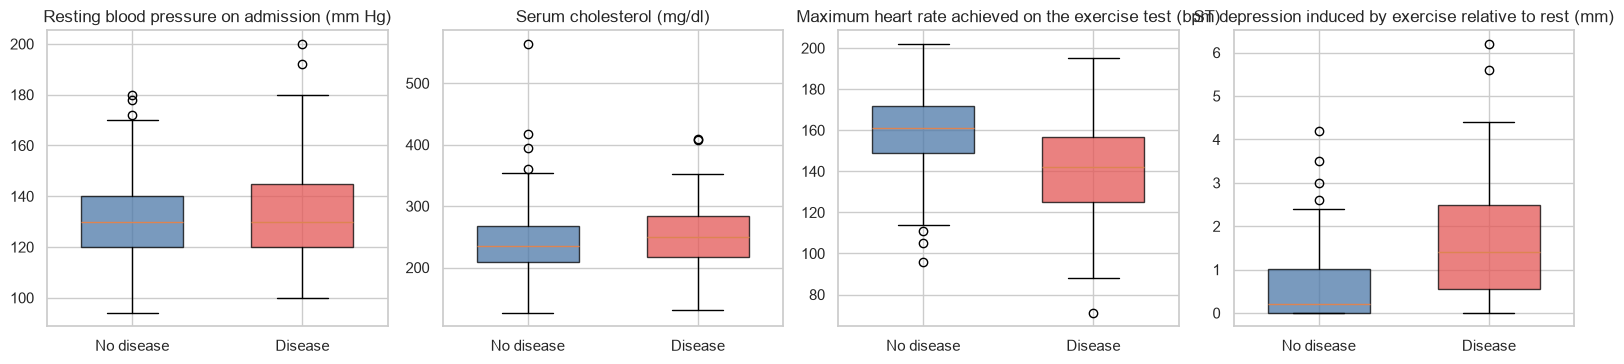

In [15]:
from scipy.stats import mannwhitneyu

plots.by_disease(df, ["trestbps", "chol", "thalach", "oldpeak"]);
for col in ["trestbps", "chol", "thalach", "oldpeak"]:
    sick, healthy = df.loc[df[cfg.TARGET] == 1, col], df.loc[df[cfg.TARGET] == 0, col]
    print(f"{col:<9} median with disease {sick.median():g}, without {healthy.median():g}; "
          f"Mann-Whitney p = {mannwhitneyu(sick, healthy).pvalue:.2g}")

**Insight:** the classic risk factors barely separate the groups. Median resting blood pressure is 130 mm Hg with and without disease, and median cholesterol is 249 against 234.5 mg/dl. Both differences are detectable (Mann-Whitney p = 0.026 and 0.035) but small next to the stress-test signals: maximum heart rate (median 142 against 161 bpm) and ST depression (1.4 against 0.2 mm) differ with p = 1.9e-13 and 6.8e-13. One possible reason is that these patients were already referred, and many may already be treated for blood pressure or cholesterol, which the data does not record. They stay in the model, but whether it needs them is tested by removing them in the feature-selection step.

## 5.8 What we carry into modelling

Each design choice below comes from a pattern found above.

| EDA finding | Evidence | Design choice |
|---|---|---|
| The imaging results are the strongest signals | disease rate 26.1% with 0 vessels vs 85.0% with 3; `ca` has the highest correlation, 0.46 (Sections 5.5, 5.6) | **Input timing:** `ca` may be measured during the target angiogram, so the reduced-input model leads the demo; the 13-feature result is retrospective (next cell, Section 13) |
| The classes are only mildly imbalanced | 139 of 303 patients (45.9%) have disease (Section 4.4) | **No resampling:** the cut-off targets recall on training predictions (Section 10), then the full rule is checked on separate folds (Section 13) |
| Women are under-represented, and their disease rate is half the men's | 97 of 303 patients; 25.8% vs 55.3% with disease (Section 5.1) | **Recall checked by sex** before anything is claimed (Section 12.2), and a warning in the app |
| Chest-pain type runs against intuition: "asymptomatic" patients have the highest rate | 72.9% for asymptomatic patients (Section 5.2) | **One-hot encoding** of the chest-pain codes, so the model learns each category's own effect |
| Classic risk factors are weak on their own | blood pressure and cholesterol barely differ between groups (Section 5.7) | Kept as inputs, but **removal tested** by drop-column cross-validation (Section 9.5) |

* **Data:** the original UCI file, validated by the data contract; the Kaggle copy is rejected (inverted labels, re-coded categories, one patient lost and one duplicated).
* **Metric:** recall on the disease class first, with specificity, ROC-AUC and calibration as constraints; accuracy is secondary.
* **Candidate engineered features:** percentage of age-predicted maximum heart rate, ST depression above 1 mm, hypertension and high-cholesterol flags. Each is kept only if cross-validation shows it helps.

*Next: validation design, feature engineering, model comparison and tuning (Sections 6–9).*

## 5.9 Input timing and the circularity check

The target is the angiographic result. `ca` is a fluoroscopy finding and might be read during that procedure. UCI provides no timestamp to prove earlier availability. `thal` is imaging whose timing is also unverified. `slope` is exercise ECG, dropped from the 10-feature model for cross-hospital completeness rather than imaging timing.

| | Retrospective 13-feature model | Main 10-feature model |
|---|---|---|
| Cleveland cross-validated ROC-AUC | 0.900 | 0.844 |
| Hungary without refitting | Cannot reliably evaluate because `ca` is nearly entirely missing | ROC-AUC 0.877; recall 0.887 at the Cleveland cut-off, below the 0.90 target |

The app leads with the 10-feature model. A switch shows the 13-feature score for comparison only. The dataset has no queue order or waiting-time outcomes; later impact figures are simulations.


## 6. Split and validation design

With 303 patients, a single train/test split is noisy: in a 61-patient test set one patient moves accuracy by 1.6 points. The original notebook made this worse by tuning on the test set and running "cross-validation" that included it (traps T5, T7). Our design:

1. **Lock away a stratified 20% test set.** It is used exactly once, in the final evaluation.
2. **Compare and tune only on the other 80%**, with stratified 5-fold cross-validation repeated 10 times. The seed is fixed, so every model is scored on the *identical* 50 folds.
3. **Report mean ± standard deviation** over the folds, and test whether a difference is real with a corrected t-test (Nadeau & Bengio, 2003), because overlapping folds make the ordinary t-test over-confident.

All preprocessing (imputation, scaling, one-hot encoding) sits inside the model pipeline, so it is re-fitted on each training fold and never sees the validation fold.

**Purpose:** create the locked split and the shared CV folds.

In [16]:
from cardiotriage import evaluation, features, models

X_train, X_test, y_train, y_test = evaluation.make_split(df)
cv = evaluation.make_cv()
n_fold_train, n_fold_valid = evaluation.fold_sizes(X_train)

print(f"Training set:      {len(X_train)} patients ({y_train.mean():.1%} with disease)")
print(f"Test set (locked): {len(X_test)} patients ({y_test.mean():.1%} with disease)")
print(f"Cross-validation:  {cv.get_n_splits()} folds ({cfg.CV_SPLITS}-fold x {cfg.CV_REPEATS} repeats), "
      f"each training on ~{n_fold_train} and validating on ~{n_fold_valid} patients")

Training set:      242 patients (45.9% with disease)
Test set (locked): 61 patients (45.9% with disease)
Cross-validation:  50 folds (5-fold x 10 repeats), each training on ~194 and validating on ~48 patients


**Insight:** the 242 training and 61 test patients both have 45.9% disease, so stratification kept the class balance identical in both parts. Every model in this report is scored on the same 50 folds of about 194 training and 48 validation patients.

### 6.1 Metric sanity check

Before trusting metric code on real folds, we check it against a tiny example worked out by hand: 10 patients, 4 with disease. The model catches 3 of the 4 sick patients and raises one false alarm among the 6 healthy ones. By hand: recall = 3/4, specificity = 5/6, precision = 3/4, accuracy = 8/10.

**Purpose:** confirm the code reproduces the hand calculation.

In [17]:
toy_true = [1, 1, 1, 1, 0, 0, 0, 0, 0, 0]
toy_pred = [1, 1, 1, 0, 1, 0, 0, 0, 0, 0]
toy = {name: round(value, 3) for name, value in evaluation.metrics_at(toy_true, toy_pred).items()}
print(toy)
assert toy == {"recall": 0.75, "specificity": 0.833, "precision": 0.75, "accuracy": 0.8}

{'recall': 0.75, 'specificity': 0.833, 'precision': 0.75, 'accuracy': 0.8}


**Insight:** the code matches the hand calculation exactly (recall 0.75, specificity 0.833, precision 0.75, accuracy 0.8). In particular, specificity, which scikit-learn has no built-in name for, is wired correctly as the recall of the "no disease" class.

## 7. Domain feature engineering

The EDA suggested four clinically meaningful features. Each is a standard clinical threshold or ratio, not a pattern mined from this data:

| Feature | Definition | Clinical rationale |
|---|---|---|
| `pct_max_hr` | `thalach / (220 − age)` | Share of the age-predicted maximum heart rate reached; failing to reach 85% is a known warning sign (Section 5.3) |
| `hypertension` | `trestbps ≥ 130` | Stage-1 hypertension threshold (ACC/AHA 2017) |
| `high_chol` | `chol ≥ 240` | High total cholesterol (NCEP) |
| `st_depression_gt1` | `oldpeak > 1` | Marked ST depression on exercise (Section 5.4) |

They are added by a step inside the pipeline (`features.add_domain_features`), so they are computed the same way in training, in the test evaluation and in the demo app. **They are kept only if cross-validation shows they help.** We test them on the two most different model families, a linear model and a tree ensemble.

**Purpose:** show the new columns for three training patients, then compare each model with and without them on the same 50 folds.

In [18]:
shown = ["age", "thalach", "pct_max_hr", "trestbps", "hypertension", "chol", "high_chol", "oldpeak", "st_depression_gt1"]
display(features.add_domain_features(X_train.head(3))[shown].round(3))

,age,thalach,pct_max_hr,trestbps,hypertension,chol,high_chol,oldpeak,st_depression_gt1
180,48.0,166.0,0.965,124.0,0,274.0,1,0.5,0
208,55.0,155.0,0.939,130.0,1,262.0,1,0.0,0
167,54.0,159.0,0.958,132.0,1,288.0,1,0.0,0


In [19]:
ablation = {}
for name in ["Logistic Regression", "Random Forest"]:
    for use_fe in (False, True):
        label = f"{name}, {'with' if use_fe else 'without'} domain features"
        ablation[label] = evaluation.cv_scores(models.zoo_pipeline(name, use_fe), X_train, y_train, cv)
display(evaluation.format_table(evaluation.cv_table(ablation))[["roc_auc", "recall", "brier"]])

deltas, p_values = [], []
for name in ["Logistic Regression", "Random Forest"]:
    with_fe = ablation[f"{name}, with domain features"]["roc_auc"]
    without = ablation[f"{name}, without domain features"]["roc_auc"]
    deltas.append(with_fe.mean() - without.mean())
    p_values.append(evaluation.corrected_ttest(with_fe, without, n_fold_train, n_fold_valid))
    print(f"{name}: ROC-AUC change {deltas[-1]:+.3f}, corrected t-test p = {p_values[-1]:.2f}")

# keep the features only if they help both families and the gain is significant for at least one
USE_FE = all(d > 0 for d in deltas) and any(p < 0.05 for p in p_values)
print(f"Decision: use domain features = {USE_FE}")

,roc_auc,recall,brier
"Logistic Regression, without domain features",0.894 ± 0.038,0.765 ± 0.075,0.128 ± 0.026
"Logistic Regression, with domain features",0.890 ± 0.038,0.762 ± 0.071,0.132 ± 0.027
"Random Forest, without domain features",0.889 ± 0.037,0.749 ± 0.077,0.136 ± 0.021
"Random Forest, with domain features",0.880 ± 0.038,0.738 ± 0.074,0.140 ± 0.021


Logistic Regression: ROC-AUC change -0.004, corrected t-test p = 0.13
Random Forest: ROC-AUC change -0.008, corrected t-test p = 0.15
Decision: use domain features = False


**Insight:** the engineered features did not help. Mean ROC-AUC moved by −0.004 for logistic regression and −0.008 for random forest, and neither change is statistically meaningful (p = 0.13 and p = 0.15). We drop them. The models already receive age, maximum heart rate, blood pressure, cholesterol and ST depression directly, so fixed clinical thresholds add no information a model cannot learn from the raw values, and when two options tie the simpler one wins.

## 8. Model comparison

We compare five model families, from a trivial floor to a strong boosted ensemble. All use the same preprocessing and the same 50 folds, with default settings (tuning comes in Section 9).

| Model | How it works | Strengths | Weaknesses | Why it is here |
|---|---|---|---|---|
| **Dummy (prior)** | Gives every patient the training-set disease rate | None; it is a floor | Cannot rank patients at all | Any useful model must clearly beat it |
| **Logistic regression** (linear) | Adds up weighted features into log-odds, then converts to a probability | Interpretable per feature, well-calibrated, stable on small data | Captures only straight-line effects unless features are engineered | The interpretable baseline a clinician can audit |
| **K-nearest neighbours** (distance) | Risk = share of disease among the *k* most similar training patients | Intuitive ("patients like this one"); no training step | Sensitive to feature scaling and irrelevant features; slow on large data | Tests whether patient similarity is enough; it was crippled by unscaled data in the original notebook (T8) |
| **Random forest** (bagging) | Averages hundreds of deep decision trees, each trained on a bootstrap sample | Captures interactions and non-linear effects; robust to outliers | Harder to explain; probabilities often less calibrated | The standard non-linear tabular baseline |
| **XGBoost** (boosting) | Adds shallow trees one at a time, each correcting the previous trees' errors | Often the most accurate on tabular data | Many settings; overfits small data if untuned | The strongest family in practice; checks whether more complexity pays off at n = 242 |

**The math, one line per model.** The setting we tune in Section 9 is in bold.

* **Dummy:** $\hat p(x) = \bar y_{\text{train}}$, the same training-set disease rate for every patient.
* **Logistic regression:** $\hat p(x) = \sigma(\beta_0 + \beta^\top x)$ with $\sigma(z) = 1/(1 + e^{-z})$; the coefficients minimise $\mathbf{C}\sum_i \text{log-loss}_i + \tfrac{1}{2}\lVert\beta\rVert^2$, so a smaller **C** shrinks every coefficient towards zero.
* **K-nearest neighbours:** $\hat p(x) = \sum_{i \in N_k(x)} w_i y_i \,/\, \sum_{i \in N_k(x)} w_i$ over the **k** closest training patients, with Minkowski distance $d(x, x') = \big(\sum_j |x_j - x'_j|^{q}\big)^{1/q}$ ($q = 1$ Manhattan, $q = 2$ Euclidean) and weights $w_i = 1$ or $1/d$.
* **Random forest:** $\hat p(x) = \frac{1}{B}\sum_{b=1}^{B} T_b(x)$; each tree $T_b$ grows on a bootstrap sample, and every split picks, from a random subset of features, the one that most reduces Gini impurity $1 - \sum_c p_c^2$; **max_depth** and the minimum leaf size stop the trees memorising patients.
* **XGBoost:** $F_m(x) = F_{m-1}(x) + \boldsymbol{\eta}\, f_m(x)$ and $\hat p(x) = \sigma(F_M(x))$; each new shallow tree $f_m$ (depth ≤ **max_depth**) is fitted to the gradient of the log-loss of the current model, with a penalty $\gamma T + \tfrac{1}{2}\lambda\lVert w\rVert^2$ on its $T$ leaf weights $w$; the **learning rate** $\eta$ and the number of trees $M$ set how fast it learns.

**Purpose:** cross-validate all five families on identical folds.

,roc_auc,pr_auc,recall,specificity,f1,brier,accuracy
Dummy (prior),0.500 ± 0.000,0.459 ± 0.007,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.248 ± 0.001,0.541 ± 0.007
Logistic Regression,0.894 ± 0.038,0.889 ± 0.046,0.765 ± 0.075,0.874 ± 0.072,0.799 ± 0.054,0.128 ± 0.026,0.824 ± 0.047
KNN,0.867 ± 0.041,0.824 ± 0.051,0.790 ± 0.065,0.830 ± 0.061,0.794 ± 0.046,0.145 ± 0.026,0.812 ± 0.042
Random Forest,0.889 ± 0.037,0.886 ± 0.040,0.749 ± 0.077,0.835 ± 0.072,0.770 ± 0.056,0.136 ± 0.021,0.796 ± 0.049
XGBoost,0.863 ± 0.039,0.864 ± 0.043,0.760 ± 0.085,0.810 ± 0.081,0.765 ± 0.057,0.169 ± 0.035,0.787 ± 0.049


Ranking by ROC-AUC: {'Logistic Regression': 0.894, 'Random Forest': 0.889, 'KNN': 0.867, 'XGBoost': 0.863}
Best vs runner-up: Logistic Regression vs Random Forest, corrected t-test p = 0.70


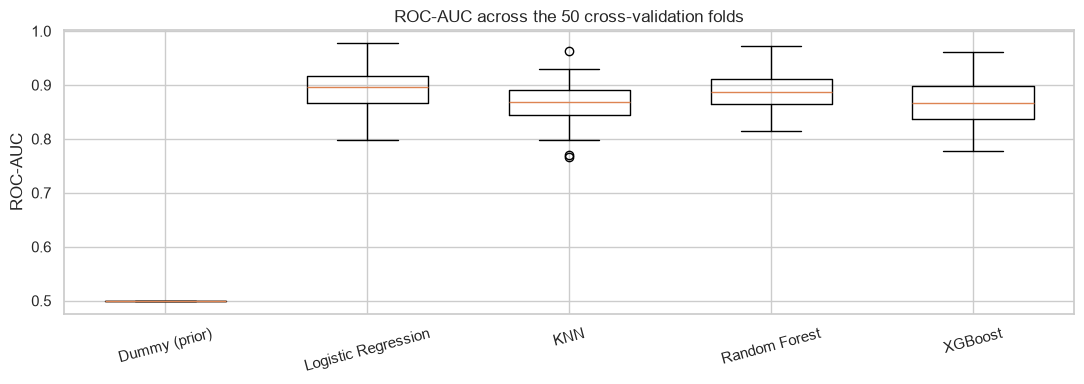

In [20]:
scores = {name: evaluation.cv_scores(models.zoo_pipeline(name, USE_FE), X_train, y_train, cv)
          for name in models.MODEL_ZOO}
comparison = evaluation.cv_table(scores)
display(evaluation.format_table(comparison))
plots.cv_boxplot(scores, "roc_auc");

ranked = comparison["roc_auc_mean"].drop("Dummy (prior)").sort_values(ascending=False)
best, runner_up = ranked.index[:2]
p = evaluation.corrected_ttest(scores[best]["roc_auc"], scores[runner_up]["roc_auc"], n_fold_train, n_fold_valid)
print(f"Ranking by ROC-AUC: {ranked.round(3).to_dict()}")
print(f"Best vs runner-up: {best} vs {runner_up}, corrected t-test p = {p:.2f}")

**Insight:** every real model beats the dummy floor (ROC-AUC 0.500) by a wide margin. Logistic regression ranks first at 0.894 ± 0.038, just ahead of random forest at 0.889; KNN (0.867) and untuned XGBoost (0.863) trail. The gap between the top two is far smaller than the fold-to-fold spread (corrected t-test p = 0.70), so it is not evidence that either is better. At the default decision cut-off every model still misses roughly a quarter of sick patients (recall 0.749 to 0.790), which is why the clinical cut-off is chosen separately in the decision layer instead of being left at the default. PR-AUC, which looks only at the disease class, gives the same top two (0.889 for logistic regression, 0.886 for random forest); the dummy's 0.459 is simply the disease rate, the PR-AUC of random guessing.

## 9. Hyperparameter tuning and model selection

Each of the four real models is tuned with a randomised search of 30 settings, scored by ROC-AUC on a 5-fold × 2-repeat CV of the training set. That CV uses **different folds** (a different seed) from the 50 comparison folds, and the test set is never touched, unlike the original notebook, which picked KNN's `k` by test score (T5) and then re-used the wrong `C` (T6). We then re-score each tuned model on the shared 50 folds.

Search spaces (`models.SEARCH_SPACES`): logistic regression `C` and class weights; KNN `k`, distance weighting and metric; random forest depth, leaf size, features per split and class weights; XGBoost number of trees, depth, learning rate, row and column sampling, child weight and L2 penalty.

*Caveat:* the same 242 patients both choose the settings and score them, so the tuned scores are slightly optimistic. The locked test set gives the honest number later.

**Purpose:** tune each model and compare default against tuned performance.

In [21]:
searches = {name: evaluation.tune(name, X_train, y_train, n_iter=30, use_fe=USE_FE) for name in models.SEARCH_SPACES}
tuned_scores = {name: evaluation.cv_scores(s.best_estimator_, X_train, y_train, cv) for name, s in searches.items()}
tuned = evaluation.cv_table(tuned_scores)

before_after = pd.DataFrame({
    "default ROC-AUC": comparison.loc[tuned.index, "roc_auc_mean"],
    "tuned ROC-AUC": tuned["roc_auc_mean"],
    "tuned SD": tuned["roc_auc_sd"],
})
before_after["change"] = before_after["tuned ROC-AUC"] - before_after["default ROC-AUC"]
display(before_after.round(3))
display(evaluation.format_table(tuned))

for name, s in searches.items():
    params = {k.replace("model__", ""): (round(v, 3) if isinstance(v, float) else v) for k, v in s.best_params_.items()}
    print(f"{name}: {params}")

,default ROC-AUC,tuned ROC-AUC,tuned SD,change
Logistic Regression,0.894,0.900,0.035,0.007
KNN,0.867,0.896,0.034,0.030
Random Forest,0.889,0.894,0.038,0.005
XGBoost,0.863,0.897,0.034,0.034


,roc_auc,pr_auc,recall,specificity,f1,brier,accuracy
Logistic Regression,0.900 ± 0.035,0.895 ± 0.042,0.770 ± 0.072,0.884 ± 0.067,0.807 ± 0.051,0.126 ± 0.023,0.832 ± 0.045
KNN,0.896 ± 0.034,0.896 ± 0.036,0.745 ± 0.065,0.900 ± 0.057,0.799 ± 0.048,0.132 ± 0.018,0.829 ± 0.041
Random Forest,0.894 ± 0.038,0.895 ± 0.038,0.771 ± 0.071,0.857 ± 0.067,0.795 ± 0.052,0.139 ± 0.016,0.818 ± 0.047
XGBoost,0.897 ± 0.034,0.895 ± 0.038,0.778 ± 0.072,0.855 ± 0.078,0.798 ± 0.048,0.129 ± 0.022,0.820 ± 0.045


Logistic Regression: {'C': np.float64(0.216), 'class_weight': None}
KNN: {'n_neighbors': 46, 'p': 1, 'weights': 'distance'}
Random Forest: {'class_weight': None, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 9}
XGBoost: {'colsample_bytree': np.float64(0.876), 'learning_rate': np.float64(0.037), 'max_depth': 3, 'min_child_weight': 8, 'n_estimators': 178, 'reg_lambda': np.float64(2.246), 'subsample': np.float64(0.894)}


**Insight:** tuning lifted every model and closed most of the gaps: XGBoost gained the most (0.863 to 0.897) once its trees were made shallow and its learning rate small, and KNN rose from 0.867 to 0.896 with many neighbours (`k` = 46) and distance weighting. Logistic regression gained least (0.894 to 0.900) because a regularised linear model has little to tune. After tuning all four models sit between 0.894 and 0.900, a spread smaller than any single model's fold-to-fold SD (0.034 to 0.038).

### 9.1 Selection

**Selection rule (fixed before looking at the results):** the highest mean CV ROC-AUC wins, but if logistic regression is within one standard deviation of the winner we ship logistic regression. It is interpretable feature by feature (a clinician can see *why* a patient scored high), its probabilities are naturally well calibrated, and its per-patient explanations are exact.

**Purpose:** apply the rule, check whether calibration would help, and record the selected model.

In [22]:
selected = evaluation.select_model(tuned)
runner_up = tuned["roc_auc_mean"].drop(selected).idxmax()
p = evaluation.corrected_ttest(tuned_scores[selected]["roc_auc"], tuned_scores[runner_up]["roc_auc"],
                               n_fold_train, n_fold_valid)
final_pipe = searches[selected].best_estimator_
print(f"Selected model: {selected}  (ROC-AUC {tuned.loc[selected, 'roc_auc_mean']:.3f} ± {tuned.loc[selected, 'roc_auc_sd']:.3f})")
print(f"Runner-up:      {runner_up}  (ROC-AUC {tuned.loc[runner_up, 'roc_auc_mean']:.3f}); corrected t-test p = {p:.2f}")
print(f"Settings:       C = {final_pipe.named_steps['model'].C:.3f}, class_weight = {final_pipe.named_steps['model'].class_weight}")

calibrated_scores = evaluation.cv_scores(evaluation.calibrated(final_pipe), X_train, y_train, cv)
brier_raw, brier_cal = tuned_scores[selected]["brier"].mean(), calibrated_scores["brier"].mean()
USE_CALIBRATION = brier_cal < brier_raw
print(f"Brier score: {brier_raw:.4f} as is, {brier_cal:.4f} with Platt calibration -> calibrate = {USE_CALIBRATION}")

Selected model: Logistic Regression  (ROC-AUC 0.900 ± 0.035)
Runner-up:      XGBoost  (ROC-AUC 0.897); corrected t-test p = 0.81
Settings:       C = 0.216, class_weight = None


Brier score: 0.1264 as is, 0.1275 with Platt calibration -> calibrate = False


**Insight:** logistic regression is the selected model, with ROC-AUC 0.900 ± 0.035, the highest of the four, so the selection rule did not even need its tie-break. The runner-up is XGBoost at 0.897, and the difference is nowhere near significant (p = 0.81): the extra complexity of boosting buys nothing on a training set this small. Extra calibration would not help: the Brier score is 0.1264 as is and 0.1275 after Platt calibration, so we keep the model's own probabilities.

### 9.2 Head-to-head at the clinical cut-off

The tables above score every model at the default 0.5 cut-off, but the triage model will not use 0.5: Section 10 sets the cut-off so that at least 90% of sick patients are flagged. To compare the models where it matters, each tuned model gets **its own** cut-off by the same rule (out-of-fold predictions on the training set, recall ≥ 0.90), and we compare what each pays for that recall: specificity, PPV and missed patients per 100. PR-AUC, which looks only at how well the disease class is ranked, is shown alongside. We also check **who** each model misses: if all four miss the same patients, the misses come from the data, not from the choice of model.

**Purpose:** compare the four tuned models at their own recall-0.90 cut-offs, with one confusion matrix each (training patients, out-of-fold).

,threshold,recall,specificity,ppv,missed_per_100,pr_auc
Logistic Regression,0.287,0.901,0.679,0.704,4.545,0.891
KNN,0.241,0.901,0.603,0.658,4.545,0.893
Random Forest,0.310,0.901,0.565,0.637,4.545,0.890
XGBoost,0.297,0.901,0.672,0.699,4.545,0.889


Sick training patients: 111; missed by at least one model: 15; missed by all 4: 6
Models missing each sick patient (count of patients): {0: 96, 1: 2, 2: 3, 3: 4, 4: 6}
Logistic Regression misses 11; 6 of them are missed by every model
Healthy training patients: 131; correctly not flagged by each model: {'Logistic Regression': 89, 'KNN': 79, 'Random Forest': 74, 'XGBoost': 88}


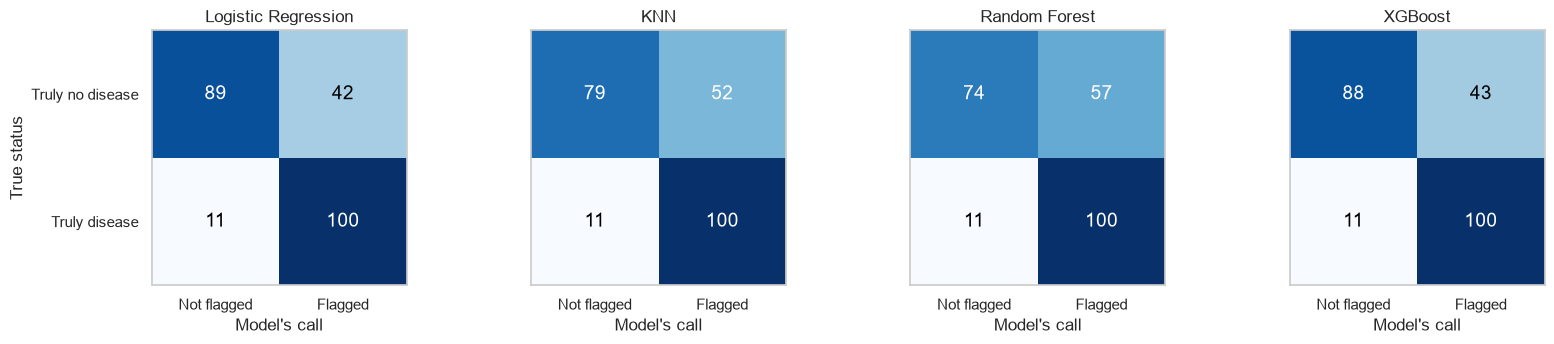

In [23]:
op_table, op_flags = evaluation.operating_points({name: s.best_estimator_ for name, s in searches.items()},
                                                X_train, y_train)
display(op_table.round(3))
plots.confusion_grid({name: evaluation.confusion(y_train, op_flags[name]) for name in op_flags});

is_sick = (y_train == 1).to_numpy()
missed_by = (~op_flags[is_sick]).sum(axis=1)                 # how many of the 4 models miss each sick patient
n_models = op_flags.shape[1]
print(f"Sick training patients: {int(is_sick.sum())}; missed by at least one model: {int((missed_by > 0).sum())}; "
      f"missed by all {n_models}: {int((missed_by == n_models).sum())}")
print("Models missing each sick patient (count of patients):", missed_by.value_counts().sort_index().to_dict())
own = ~op_flags.loc[is_sick, selected]
print(f"{selected} misses {int(own.sum())}; {int((missed_by[own] == n_models).sum())} of them are missed by every model")
healthy = ~is_sick
print(f"Healthy training patients: {int(healthy.sum())}; correctly not flagged by each model:",
      (~op_flags[healthy]).sum().astype(int).to_dict())

**Insight:** at the clinical cut-off logistic regression and XGBoost are tied, and both beat the other two. All four reach the same recall (0.901, 4.545 sick patients missed per 100). Of the 131 healthy training patients, logistic regression correctly leaves 89 unflagged (specificity 0.679) and XGBoost 88 (0.672): a single patient, far too small a gap to call either better. KNN (79, specificity 0.603) and random forest (74, 0.565) send noticeably more healthy patients into the priority queue for the same recall. Out-of-fold PR-AUC is almost identical (0.889 to 0.893), so the differences lie in how cleanly each model separates the borderline patients, not in overall ranking. The misses are largely shared: 6 sick patients are missed by all 4 models, and 6 of the 11 that logistic regression misses are among them. These patients look reassuring on every recorded feature (see the clinical-safety section), so another algorithm would not find them; more or richer data might. With logistic regression and XGBoost tied, the selection rule keeps the simpler, interpretable model.

### 9.3 How optimistic is the tuned score? Nested cross-validation

The tuned scores in Section 9 are, in principle, optimistic: the same 242 patients chose each model's settings and then scored them. Nested cross-validation removes that bias. An outer 5-fold split holds out one fold, the **whole** random search runs on the other four, and the held-out fold scores the result, so the held-out patients never influence the settings. Because the search runs five more times per model, we run it for the two models whose comparison matters, the selected model and the runner-up (adding random forest alone would more than double the notebook's run time).

**Purpose:** measure how much tuning on the training set inflated the ROC-AUC.

In [24]:
nested = {name: evaluation.nested_cv(name, X_train, y_train, use_fe=USE_FE) for name in [selected, runner_up]}
optimism = pd.DataFrame({
    "tuned (50 folds, settings chosen on the same patients)": tuned.loc[list(nested), "roc_auc_mean"],
    "nested (5 outer folds, unbiased)": {name: s.mean() for name, s in nested.items()},
    "nested SD": {name: s.std(ddof=1) for name, s in nested.items()},
})
optimism["optimism (tuned - nested)"] = optimism.iloc[:, 0] - optimism.iloc[:, 1]
display(optimism.round(3))

,"tuned (50 folds, settings chosen on the same patients)","nested (5 outer folds, unbiased)",nested SD,optimism (tuned - nested)
Logistic Regression,0.900,0.909,0.031,-0.008
XGBoost,0.897,0.905,0.046,-0.007


**Insight:** tuning did not inflate the scores. The nested estimate is 0.909 (SD 0.031) for logistic regression and 0.905 (SD 0.046) for XGBoost, slightly *above* their tuned 0.900 and 0.897, so the measured optimism is −0.008 and −0.007, far smaller than the fold-to-fold spread. A negative value means no detectable bias, not a real gain: five outer folds are a different and noisier split. With only one setting to tune (`C`), logistic regression has little room to overfit its search, so the tuned figures and the selection built on them stand.

### 9.4 Would more data help?

**Purpose:** train the selected model on growing subsets of the training set and watch the validation ROC-AUC.

,train_size,train_mean,train_sd,valid_mean,valid_sd
0,38,0.964,0.022,0.861,0.055
1,77,0.942,0.023,0.874,0.051
2,115,0.934,0.012,0.889,0.043
3,154,0.930,0.011,0.896,0.039
4,193,0.929,0.007,0.900,0.036


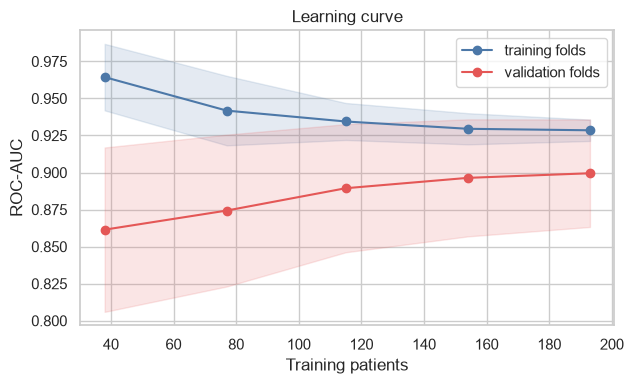

In [25]:
curve = evaluation.learning_curve_table(final_pipe, X_train, y_train)
plots.learning_curve(curve);
display(curve.round(3))

**Insight:** validation ROC-AUC climbs from 0.861 with 38 training patients to 0.900 with 193, while training ROC-AUC falls from 0.964 to 0.929, so the two curves are converging and the model is not overfitting. The validation curve has not flattened yet, which says more patients would still help. That is the strongest argument for the external data discussed in the next steps.

### 9.5 Feature selection: does every feature earn its place?

Section 7 tested *adding* features. Here we test *removing* them: drop one clinical feature at a time from the tuned model, re-score on the same 50 folds, and compare with the full model using the corrected t-test. Then we drop, together, every feature whose removal did not hurt, and check whether that smaller model is better. **Rule (fixed before looking):** keep all 13 features unless the smaller model is better with p < 0.05, the same bar the engineered features had to clear.

**Purpose:** drop-column importance and a one-step backward elimination for the selected model.

In [26]:
base = tuned_scores[selected]["roc_auc"]
drop_rows = {}
for f in cfg.FEATURES:
    s = evaluation.cv_scores(models.build_pipeline(final_pipe[-1], USE_FE, drop=[f]), X_train, y_train, cv)["roc_auc"]
    drop_rows[f] = {"ROC-AUC without it": s.mean(), "change": s.mean() - base.mean(),
                    "corrected p": evaluation.corrected_ttest(s, base, n_fold_train, n_fold_valid)}
drop_table = pd.DataFrame(drop_rows).T.sort_values("change")
display(drop_table.round(3))

removable = list(drop_table.index[drop_table["change"] >= 0])
reduced = evaluation.cv_scores(models.build_pipeline(final_pipe[-1], USE_FE, drop=removable), X_train, y_train, cv)["roc_auc"]
p_reduced = evaluation.corrected_ttest(reduced, base, n_fold_train, n_fold_valid)
print(f"All 13 features: ROC-AUC {base.mean():.3f}")
print(f"Without the {len(removable)} features whose removal did not hurt ({', '.join(removable)}): ROC-AUC "
      f"{reduced.mean():.3f}, change {reduced.mean() - base.mean():+.3f}, corrected t-test p = {p_reduced:.2f}")
smaller_wins = reduced.mean() > base.mean() and p_reduced < 0.05
print("Decision:", "a smaller feature set is significantly better" if smaller_wins else "keep all 13 features")

,ROC-AUC without it,change,corrected p
ca,0.870,-0.030,0.016
thal,0.888,-0.012,0.322
cp,0.889,-0.011,0.235
sex,0.891,-0.010,0.108
slope,0.896,-0.004,0.483
thalach,0.899,-0.002,0.804
exang,0.900,-0.000,0.924
age,0.900,0.000,0.954
restecg,0.901,0.001,0.860
trestbps,0.901,0.001,0.855


All 13 features: ROC-AUC 0.900
Without the 6 features whose removal did not hurt (age, restecg, trestbps, chol, fbs, oldpeak): ROC-AUC 0.907, change +0.007, corrected t-test p = 0.47
Decision: keep all 13 features


**Insight:** only one feature is indispensable on its own: removing `ca` (vessels seen on fluoroscopy) drops ROC-AUC from 0.900 to 0.870 (p = 0.016). Removing `thal`, chest-pain type or sex costs 0.010 to 0.012, not significant on its own because these features overlap. Six features cost nothing when removed one at a time (age, resting ECG, blood pressure, cholesterol, fasting blood sugar and ST depression), and dropping all six together gives 0.907 (+0.007). That gain is well inside the noise (p = 0.47), and the six were picked on the same folds, so it is optimistic. By the rule fixed in advance we keep all 13 features: the smaller model is not reliably better, and age and ST depression are established signals that a cardiologist expects to see in the explanation.

### 9.6 Was a 30-setting search enough?

**Purpose:** re-run the search with 100 settings for the selected model and the runner-up, on the same tuning folds, and see whether the best score moves.

In [27]:
budget = {}
for name in [selected, runner_up]:
    wider = evaluation.tune(name, X_train, y_train, n_iter=100, use_fe=USE_FE)
    budget[name] = {"30 settings": searches[name].best_score_, "100 settings": wider.best_score_}
budget = pd.DataFrame(budget).T
budget["gain"] = budget["100 settings"] - budget["30 settings"]
print("Best tuning-CV ROC-AUC by search size:")
display(budget.round(3))

Best tuning-CV ROC-AUC by search size:


,30 settings,100 settings,gain
Logistic Regression,0.898,0.898,0.000
XGBoost,0.893,0.896,0.003


**Insight:** 30 settings were enough. With 100 settings the best tuning score of logistic regression does not move (0.898 both times), because it has only one real setting to tune. XGBoost gains 0.003 (0.893 to 0.896): it stays below logistic regression, and the gain is far smaller than the fold-to-fold spread, so a bigger search would not change the model we ship. Bayesian optimisation (for example Optuna) stays in the next steps for the tree models, whose search spaces are large.

### Model carried into the decision layer

* **Model:** tuned logistic regression on the 13 raw features (no domain features, no extra calibration).
* **Why:** the best cross-validated ROC-AUC, interpretable, well calibrated, and no more complex model is significantly better.
* **Open item:** at the default 0.5 cut-off its recall is far below our 0.90 target, so the next step is to choose clinical cut-offs from out-of-fold predictions.

*Next: the decision layer, the final test evaluation and the clinical safety checks (Sections 10–12).*

## 10. Decision layer: from a probability to a clinical action

The following Sections 10–12 evaluate the retrospective 13-feature model. The main reduced-input decision rule is assessed in Section 13. A probability is not a decision. The default cut-off of 0.5 is arbitrary, and at that cut-off the model misses about a quarter of sick patients (Section 8). We choose the cut-offs ourselves, from **out-of-fold predictions**: every training patient is scored by a model that never saw them (5-fold, averaged over 10 repeats), but these same patients still select and assess the cut-offs. The test set is still untouched.

*Caveat:* the model's setting (`C`) was itself chosen on these 242 patients, so the out-of-fold risks could be slightly optimistic. Nested CV in Section 9.3 evaluates ROC-AUC tuning only. Section 13 repeats tuning and threshold selection within outer folds before assessing tiers. The locked test in Section 11 assesses only the retrospective 13-feature rule.

* **Low cut-off:** the highest cut-off that still flags at least 90% of patients with disease. Below it, a patient goes to the Low tier.
* **High cut-off:** the lowest cut-off at which at least 85% of the patients above it truly have disease. Above it, a patient goes to the High tier (priority angiography).

**Purpose:** compute out-of-fold risks, choose both cut-offs, and compare them with the default.

Low cut-off  (recall >= 90%): 0.287
High cut-off (PPV >= 85%):    0.509


,cut-off,threshold,recall,specificity,ppv,npv,flagged_per_100,caught_per_100,missed_per_100
0,low (chosen),0.287,0.901,0.679,0.704,0.890,58.7,41.3,4.5
1,default,0.500,0.784,0.885,0.853,0.829,42.1,36.0,9.9
2,high (chosen),0.509,0.784,0.885,0.853,0.829,42.1,36.0,9.9


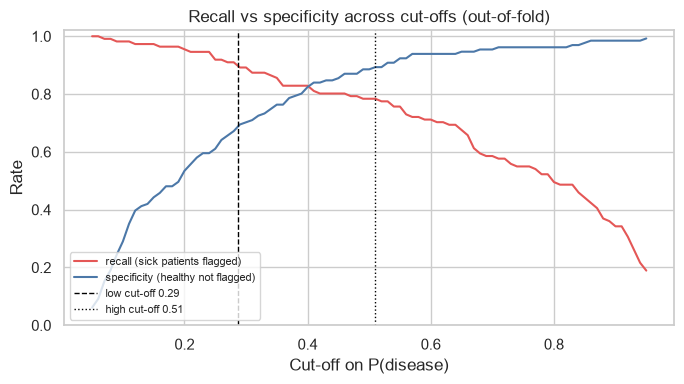

In [28]:
from cardiotriage import triage

oof = evaluation.oof_proba(final_pipe, X_train, y_train)
thresholds = triage.pick_thresholds(y_train, oof)
print(f"Low cut-off  (recall >= {cfg.RECALL_TARGET:.0%}): {thresholds['low']:.3f}")
print(f"High cut-off (PPV >= {cfg.PPV_TARGET:.0%}):    {thresholds['high']:.3f}")

sweep = evaluation.threshold_sweep(y_train, oof, np.round(np.arange(0.05, 0.96, 0.01), 2))
plots.threshold_tradeoff(sweep, thresholds);

compare = evaluation.threshold_sweep(y_train, oof, [thresholds["low"], 0.5, thresholds["high"]])
compare.insert(0, "cut-off", ["low (chosen)", "default", "high (chosen)"])
per_100 = ["flagged_per_100", "caught_per_100", "missed_per_100"]
display(compare.round(3).assign(**{c: compare[c].round(1) for c in per_100}))

**Insight:** out-of-fold, the low cut-off is 0.287 and the high cut-off 0.509. At the low cut-off the model flags sick patients with recall 0.901 while still clearing most healthy ones (specificity 0.679). Per 100 patients that means 58.7 flagged, 41.3 sick patients caught and 4.5 missed. The default cut-off would miss 9.9 per 100, more than twice as many, while flagging 42.1. The high cut-off lands almost exactly on the default, so the High tier means "as sure as a standard yes", with a PPV of 0.853.

### 10.1 Is acting on the model worth it? Decision-curve analysis

Recall and specificity do not say whether using the model beats simpler policies. Decision-curve analysis (Vickers & Elkin, 2006) does: for each "risk at which angiography is worth it", it computes the **net benefit**, the share of patients correctly sent to angiography minus the false alarms, weighted by how many false alarms that risk level tolerates. The model is useful wherever its curve lies above both "angiography for everyone" and "angiography for no one".

**Purpose:** compute net benefit on the out-of-fold risks.

,model,treat_all,treat_none
threshold,,,
0.1,0.408,0.399,0.0
0.2,0.375,0.323,0.0
0.3,0.340,0.227,0.0
0.5,0.298,-0.083,0.0


Model beats both policies at every risk level from 0.05 to 0.80


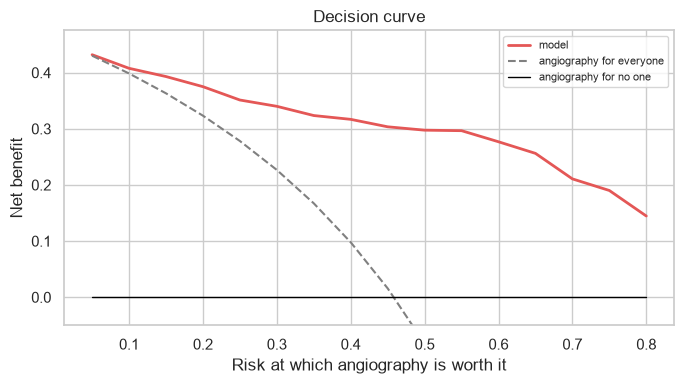

In [29]:
dca = evaluation.net_benefit(y_train, oof, np.round(np.arange(0.05, 0.81, 0.05), 2))
plots.decision_curve(dca);
display(dca[dca["threshold"].isin([0.1, 0.2, 0.3, 0.5])].round(3).set_index("threshold"))
above_both = dca[(dca["model"] > dca["treat_all"]) & (dca["model"] > dca["treat_none"])]["threshold"]
print(f"Model beats both policies at every risk level from {above_both.min():.2f} to {above_both.max():.2f}")

**Insight:** the model's net benefit is above both "angiography for everyone" and "angiography for no one" at every risk level from 0.05 to 0.80, so acting on it is never worse than either simple policy. The advantage is small when the bar for angiography is very low (net benefit 0.408 against 0.399 at a 0.1 risk threshold, where almost everyone would be sent anyway) and grows as the bar rises: at 0.3 the model reaches 0.340 against 0.227, and at 0.5 it is 0.298 while sending everyone becomes harmful (−0.083).

### 10.2 The three triage tiers

**Purpose:** place every training patient in a tier using their out-of-fold risk, and check how much disease each tier really contains.

In [30]:
oof_tiers = pd.Series([triage.triage(p, thresholds)["tier"] for p in oof], index=y_train.index)
tiers = pd.crosstab(oof_tiers, y_train.map({0: "no disease", 1: "disease"})).reindex(["High", "Medium", "Low"])
tiers["patients"] = tiers.sum(axis=1)
tiers["disease rate %"] = (100 * tiers["disease"] / tiers["patients"]).round(1)
tiers["action"] = [cfg.TIER_ACTIONS[t] for t in tiers.index]
display(tiers[["patients", "disease", "no disease", "disease rate %", "action"]])

disease,patients,disease,no disease,disease rate %,action
row_0,,,,,
High,102,87,15,85.3,Priority angiography
Medium,40,13,27,32.5,Cardiology review or further testing
Low,100,11,89,11.0,Clinician review and a documented safety-net plan


**Insight:** the tiers separate risk sharply. The High tier holds 102 patients, of whom 87 have disease (85.3%); the Medium tier 40 patients at 32.5%; the Low tier 100 patients at 11.0%. The 11 sick patients left in the Low tier are the price of the recall target, which is why the Low-tier action is clinician review with a documented safety-net plan. These counts describe the retrospective 13-feature rule.

### 10.3 What changes for the angiography queue?

This is a simulation. The dataset has no actual arrival sequence, queue order or waiting-time outcome. We compare risk ordering with a proportional-arrival benchmark. Two simulated views, both on the retrospective 13-feature model out-of-fold risks of the 242 training patients:

1. A **queue-gain curve**: the share of all sick patients served after the first x% of angiography slots, against a hypothetical proportional-arrival benchmark.
2. The tiers scaled to **1,000 referred patients**, the unit a service manager plans with.

The Medicare payment scenario in Section 15.2 assumes Low-tier patients do not receive angiography. It does not measure savings.

**Purpose:** quantify how much earlier sick patients reach angiography, and what the tiers mean for a cardiology service.

,model,proportional_benchmark
share of slots,,
0.2,41.4,20.0
0.4,76.6,40.0
0.6,91.0,60.0


Disease rate among all referred (training) patients: 45.9%
High: 42.1% of patients, 78.4% of all sick patients, disease rate 85.3%
High + Medium: 58.7% of patients, 90.1% of all sick patients, disease rate 70.4%

Per 1,000 referred patients:


,patients,disease,no disease,action
tier,,,,
High,421.5,359.5,62.0,Priority angiography
Medium,165.3,53.7,111.6,Cardiology review or further testing
Low,413.2,45.5,367.8,Clinician review and a documented safety-net plan
Total,1000.0,458.7,541.3,


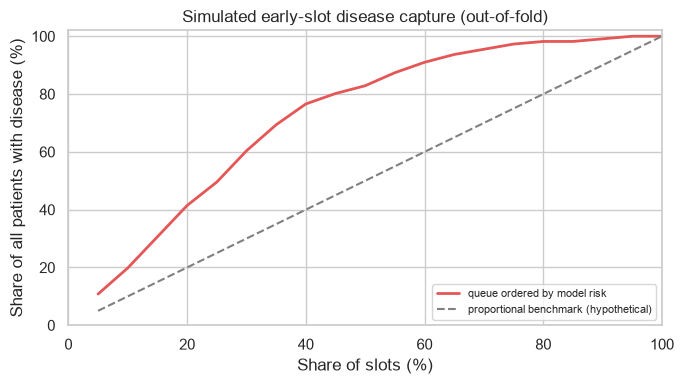

In [31]:
gain = evaluation.queue_gain(y_train, oof, np.round(np.arange(0.05, 1.001, 0.05), 2))
plots.queue_gain(gain);
display((gain.set_index("slots").loc[[0.2, 0.4, 0.6]] * 100).round(1).rename_axis("share of slots"))

n_train, n_sick = len(y_train), int(y_train.sum())
print(f"Disease rate among all referred (training) patients: {n_sick / n_train:.1%}")
for name, rows in [("High", ["High"]), ("High + Medium", ["High", "Medium"])]:
    t = tiers.loc[rows, ["patients", "disease"]].sum()
    print(f"{name}: {t['patients'] / n_train:.1%} of patients, {t['disease'] / n_sick:.1%} of all sick patients, "
          f"disease rate {t['disease'] / t['patients']:.1%}")

per_1000 = tiers[["patients", "disease", "no disease"]] * 1000 / n_train
per_1000.loc["Total"] = per_1000.sum()
per_1000 = per_1000.round(1).rename_axis(index="tier", columns=None)
per_1000["action"] = [cfg.TIER_ACTIONS.get(t, "") for t in per_1000.index]
print()
print("Per 1,000 referred patients:")
display(per_1000)

**Insight:** simulated risk ordering concentrates sick patients in earlier slots. After the first 40% of slots, 76.6% of all sick patients would be served, against 40.0% under a proportional-arrival benchmark (41.4% against 20.0% after the first fifth, 91.0% against 60.0% after 60%). The High tier is 42.1% of referred patients but holds 78.4% of all sick patients, at a disease rate of 85.3% against 45.9% overall, so the simulated yield in the priority tier is nearly double the cohort rate. Per 1,000 referred patients that means about 421.5 in High (359.5 of them sick) and 413.2 in Low, of whom 45.5 are sick: patients needing clinician review and a documented safety-net plan. No waits or avoided procedures were observed.

## 11. Final evaluation on the locked test set (used once)

Everything so far, including the model, its settings and both cut-offs, was decided on the 242 training patients. We now score the 61 test patients **for the first and only time**. Nothing below is used to change the model.

A patient counts as "flagged" when they land in the Medium or High tier (risk ≥ low cut-off). Each metric comes with a 95% confidence interval from 1,000 patient-level bootstrap resamples. Because the test set is small, these intervals are wide, and they are the honest way to read the numbers.

**Purpose:** score the test set and report every metric with its uncertainty.

,point,lo,hi
roc_auc,0.961,0.902,0.998
recall,1.000,1.000,1.000
specificity,0.667,0.500,0.829
ppv,0.718,0.579,0.854
npv,1.000,1.000,1.000
brier,0.084,0.049,0.128


Test patients: 61
Sick patients flagged: 28 of 28; exact (Clopper-Pearson) 95% CI 0.877 to 1.000
Healthy patients flagged: 11 of 33
For comparison, cross-validated ROC-AUC on the training set: 0.900


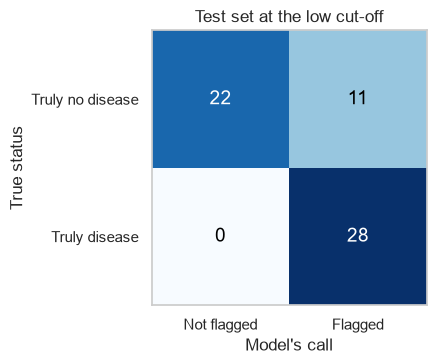

In [32]:
p_test = final_pipe.predict_proba(X_test)[:, 1]
flag_test = p_test >= thresholds["low"]
test_ci = evaluation.bootstrap_ci(y_test, p_test, thresholds["low"])
display(test_ci.round(3))

cm = evaluation.confusion(y_test, flag_test)
plots.confusion(cm);
caught, sick = int(cm.loc["Truly disease", "Flagged"]), int(y_test.sum())
recall_lo, recall_hi = evaluation.exact_ci(caught, sick)
print(f"Test patients: {len(y_test)}")
print(f"Sick patients flagged: {caught} of {sick}; exact (Clopper-Pearson) 95% CI {recall_lo:.3f} to {recall_hi:.3f}")
print(f"Healthy patients flagged: {int(cm.loc['Truly no disease', 'Flagged'])} of {int((y_test == 0).sum())}")
print(f"For comparison, cross-validated ROC-AUC on the training set: {tuned.loc[selected, 'roc_auc_mean']:.3f}")

**Insight:** on the 61 test patients the model caught every one of the 28 sick patients and flagged 11 of 33 healthy ones (specificity 0.667, 95% CI 0.500 to 0.829). A bootstrap cannot show uncertainty for a perfect score (its interval collapses to 1.000), so for recall we report the exact Clopper–Pearson interval: **0.877 to 1.000**. Test ROC-AUC is 0.961 (0.902 to 0.998), higher than the cross-validated 0.900. With so few test patients the interval is wide, and we treat the cross-validated figure as the realistic expectation: this test set was simply on the easier side.

**Purpose:** check ranking quality and calibration on the test set, and how the test patients spread over the tiers.

disease,disease,no disease
row_0,,
High,26,5
Medium,2,6
Low,0,22


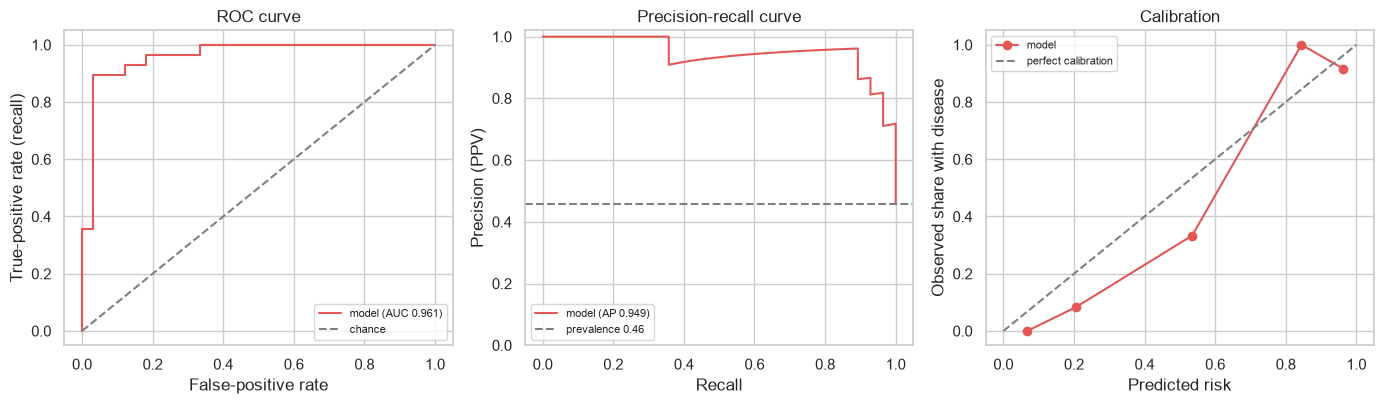

In [33]:
plots.roc_pr_calibration(evaluation.curves(y_test, p_test));
test_tiers = pd.Series([triage.triage(p, thresholds)["tier"] for p in p_test], index=y_test.index)
by_tier = pd.crosstab(test_tiers, y_test.map({0: "no disease", 1: "disease"})).reindex(["High", "Medium", "Low"]).fillna(0).astype(int)
display(by_tier)

**Insight:** no test patient with disease fell into the Low tier: the 22 Low-tier test patients were all healthy, while the High tier held 26 sick and 5 healthy patients. The calibration panel shows the model over-stating risk in the middle of the range (points below the diagonal), which errs on the side of caution. With only about a dozen patients per point this is noisy, and the cross-validated Brier score showed good calibration overall, but a new hospital should re-check calibration before trusting the displayed risk as an exact probability.

## 12. Retrospective model: clinical safety

A good average can hide the patients who matter most. This section looks at who the model misses, whether it works equally well for women and men and across ages, and at three individual patients.

### 12.1 Who does the model miss?

**Purpose:** list sick patients placed in the Low tier: on the test set, and on the training set using out-of-fold risks (a much larger sample of honest predictions).

In [34]:
fn_test = X_test[(y_test == 1).to_numpy() & ~flag_test]
print(f"Test patients with disease placed in the Low tier: {len(fn_test)}")

missed_mask = (y_train == 1).to_numpy() & (oof < thresholds["low"])
missed = X_train[missed_mask].assign(oof_risk=oof[missed_mask].round(3)).sort_values("oof_risk")
print(f"Training patients with disease that out-of-fold predictions place in Low: {len(missed)} of {int(y_train.sum())}")
shown = missed[["oof_risk", "age", "sex", "cp", "exang", "oldpeak", "ca", "thal"]].copy()
for col in ["sex", "cp", "exang", "thal"]:
    shown[col] = shown[col].map(lambda v, c=col: cfg.LABELS[c].get(int(v), "missing") if v == v else "missing")
display(shown)
print("Missed patients by sex:", shown["sex"].value_counts().to_dict())
print("Missed patients by chest pain:", shown["cp"].value_counts().to_dict())

Test patients with disease placed in the Low tier: 0
Training patients with disease that out-of-fold predictions place in Low: 11 of 111


,oof_risk,age,sex,cp,exang,oldpeak,ca,thal
145,0.061,47.0,male,non-anginal pain,no exercise angina,0.0,0.0,normal
32,0.080,64.0,male,non-anginal pain,no exercise angina,0.0,0.0,normal
44,0.119,61.0,female,asymptomatic,no exercise angina,0.0,0.0,normal
184,0.154,60.0,female,asymptomatic,no exercise angina,0.0,0.0,normal
199,0.192,59.0,male,typical angina,no exercise angina,0.0,0.0,normal
301,0.206,57.0,female,atypical angina,no exercise angina,0.0,1.0,normal
16,0.242,48.0,male,atypical angina,no exercise angina,1.0,0.0,reversible defect
294,0.245,63.0,female,asymptomatic,exercise angina,0.0,0.0,normal
22,0.249,58.0,male,atypical angina,no exercise angina,1.8,0.0,normal
278,0.267,57.0,male,atypical angina,no exercise angina,0.0,1.0,normal


Missed patients by sex: {'male': 7, 'female': 4}
Missed patients by chest pain: {'atypical angina': 4, 'non-anginal pain': 3, 'asymptomatic': 3, 'typical angina': 1}


**Insight:** no test patient was missed, but out-of-fold predictions would have missed 11 of the 111 sick training patients, so misses do happen. These patients look reassuring on the model's strongest signals: almost all have no vessels coloured on fluoroscopy and a normal thallium scan, and most had no exercise angina. The model rates them low for clinically understandable reasons, which is exactly the group safety-netting advice is for. 4 of the 11 are women. Patient 184, the woman with disease whom the Kaggle copy silently dropped, is one of them.

### 12.2 Does it work equally well for every group?

**Purpose:** recall by sex and age band on the out-of-fold training predictions (larger groups than the test set), with exact 95% intervals.

In [35]:
def with_exact_ci(table):
    ci = [evaluation.exact_ci(c, n) if n else (np.nan, np.nan) for c, n in zip(table["caught"], table["with_disease"])]
    return table.assign(recall=table["recall"].round(3), ci_low=[round(a, 3) for a, _ in ci], ci_high=[round(b, 3) for _, b in ci])

age_band = pd.cut(X_train["age"], [0, 49, 59, 120], labels=["under 50", "50-59", "60 and over"])
display(with_exact_ci(evaluation.subgroup_recall(X_train["sex"].map(cfg.LABELS["sex"]), y_train, oof, thresholds["low"])))
display(with_exact_ci(evaluation.subgroup_recall(age_band, y_train, oof, thresholds["low"])))

,patients,with_disease,caught,recall,ci_low,ci_high
group,,,,,,
female,77,18,14,0.778,0.524,0.936
male,165,93,86,0.925,0.851,0.969


,patients,with_disease,caught,recall,ci_low,ci_high
group,,,,,,
50-59,100,48,44,0.917,0.800,0.977
60 and over,73,42,38,0.905,0.774,0.973
under 50,69,21,18,0.857,0.637,0.970


**Insight:** recall is 0.925 for men (86 of 93) but only 0.778 for women (14 of 18). With just 18 sick women the exact intervals overlap (0.524 to 0.936 against 0.851 to 0.969), so the gap could be chance. But it points the same way as the missed-heart-attack literature, so we treat it as a **known gap**, not a pass. By age, recall is lowest under 50 (0.857, 18 of 21) and 0.917 and 0.905 in the two older groups.

### 12.3 Three patients up close

For each patient we show the risk, the tier, and the **contribution** of each clinical feature: how far it pushes this patient's log-odds of disease above (red) or below (blue) the average training patient. For logistic regression these are exact SHAP values, so they add up to the patient's total difference from average.

The three cases: (A) the test patient the model is most sure about, (B) the test patient closest to the low cut-off, and (C) the sick training patient the out-of-fold predictions rated lowest, since no test patient with disease was missed.

**Purpose:** explain three individual predictions.

A: most certain (test): patient 62, risk 0.993 -> High (Priority angiography); true status: disease
   top factors: {'ca': 2.33, 'thal': 0.72, 'cp': 0.49, 'slope': 0.37}
B: borderline (test): patient 66, risk 0.296 -> Medium (Cardiology review or further testing); true status: disease
   top factors: {'ca': -0.59, 'cp': -0.59, 'thal': -0.51, 'oldpeak': 0.41}


C: hardest miss (training, out-of-fold): patient 145, risk 0.063 -> Low (Clinician review and a documented safety-net plan); true status: disease
   top factors: {'ca': -0.59, 'cp': -0.59, 'thal': -0.51, 'slope': -0.34}
Case C out-of-fold risk was 0.061 (the model above was trained with this patient included)


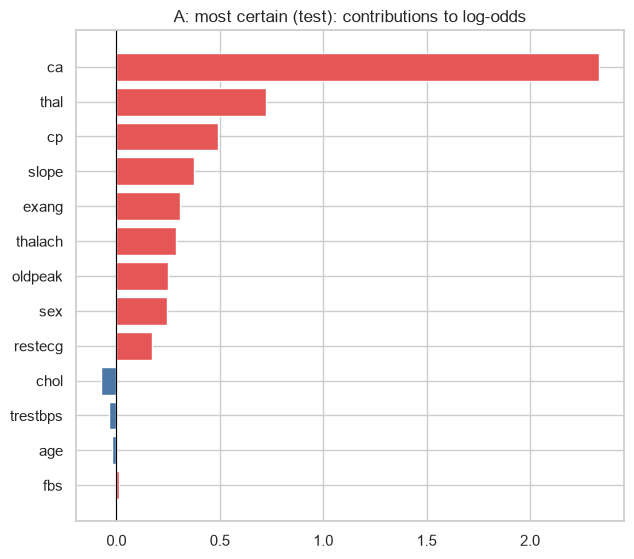

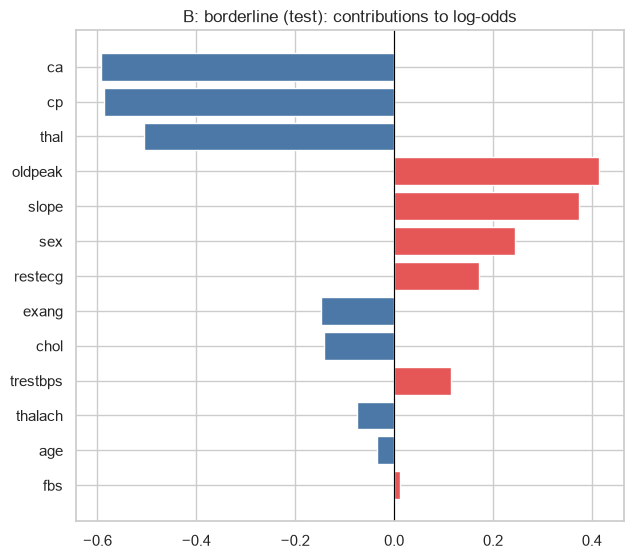

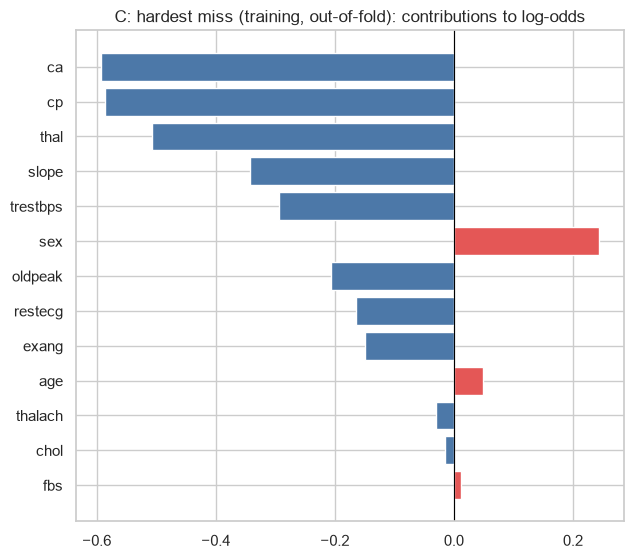

In [36]:
base = triage.baseline(final_pipe, X_train)
cases = {
    "A: most certain (test)": X_test.loc[[X_test.index[np.argmax(p_test)]]],
    "B: borderline (test)": X_test.loc[[X_test.index[np.argmin(np.abs(p_test - thresholds["low"]))]]],
    "C: hardest miss (training, out-of-fold)": X_train.loc[[missed.index[0]]],
}
truth = pd.concat([y_train, y_test])
for name, patient in cases.items():
    risk = final_pipe.predict_proba(patient)[0, 1]
    t = triage.triage(risk, thresholds)
    contrib = triage.contributions(final_pipe, patient, base)
    print(f"{name}: patient {patient.index[0]}, risk {risk:.3f} -> {t['tier']} ({t['action']}); "
          f"true status: {'disease' if truth[patient.index[0]] else 'no disease'}")
    print("   top factors:", contrib.head(4).round(2).to_dict())
    plots.importance(contrib, f"{name}: contributions to log-odds");
print(f"Case C out-of-fold risk was {missed['oof_risk'].iloc[0]:.3f} (the model above was trained with this patient included)")

**Insight:** (A) patient 62 is rated 0.993 and placed in High, driven mainly by vessels seen on fluoroscopy (+2.33), the thallium result (+0.72) and chest-pain type (+0.49); the patient does have disease. (B) Patient 66 sits just above the low cut-off at 0.296: normal imaging and chest-pain type pull the risk down (−0.59, −0.59, −0.51), but marked ST depression (+0.41) pushes it into the Medium tier. The patient has disease, so this is a close call that went the right way. (C) Patient 145 has disease but is rated 0.063 (0.061 out-of-fold): every strong signal looks reassuring, so the model cannot see this disease from these features. The explanation tells the clinician *why* the score is low, which is what makes a miss like this reviewable.

## 13. Main pre-angiography model and external validation

Everything so far comes from one hospital. The UCI collection also holds 294 patients from the **Hungarian Institute of Cardiology, Budapest**. That hospital rarely recorded `ca`, `thal` or `slope` (most values are missing), so we independently tune logistic regression on the **10 features both hospitals record**, train it on the Cleveland training set, choose its own cut-off from out-of-fold predictions, and then score Hungary without any refitting. This is the **main demo model** because it excludes `ca` and `thal`. `slope` is exercise ECG, excluded for cross-hospital completeness. It is saved alongside the retrospective 13-feature comparison.

**Purpose:** measure how much performance survives the move to a new hospital.

In [37]:
DROP = ["ca", "thal", "slope"]
model10 = evaluation.tune("Logistic Regression", X_train, y_train, n_iter=10, drop=DROP).best_estimator_
cv10 = evaluation.cv_scores(model10, X_train, y_train, cv)
th10 = triage.pick_thresholds(y_train, evaluation.oof_proba(model10, X_train, y_train))
model10.fit(X_train, y_train)

hungary = data.load_hungarian()
p_hun = model10.predict_proba(hungary[cfg.FEATURES])[:, 1]
print(f"Hungary: {len(hungary)} patients, {hungary[cfg.TARGET].mean():.1%} with disease; "
      f"missing share of dropped columns: {hungary[DROP].isna().mean().round(2).to_dict()}")
print(f"10-feature model, Cleveland cross-validated ROC-AUC: {cv10['roc_auc'].mean():.3f} ± {cv10['roc_auc'].std():.3f}")
print(f"10-feature low cut-off (from Cleveland out-of-fold risks): {th10['low']:.3f}")
display(evaluation.bootstrap_ci(hungary[cfg.TARGET], p_hun, th10["low"]).round(3))

Hungary: 294 patients, 36.1% with disease; missing share of dropped columns: {'ca': 0.99, 'thal': 0.9, 'slope': 0.65}
10-feature model, Cleveland cross-validated ROC-AUC: 0.844 ± 0.045
10-feature low cut-off (from Cleveland out-of-fold risks): 0.263


,point,lo,hi
roc_auc,0.877,0.828,0.918
recall,0.887,0.820,0.944
specificity,0.628,0.565,0.696
ppv,0.573,0.494,0.646
npv,0.908,0.852,0.954
brier,0.131,0.108,0.156


**Insight:** the independently tuned reduced-input model reaches Cleveland cross-validated ROC-AUC 0.844 and Budapest ROC-AUC 0.877 (bootstrap interval 0.828 to 0.918). At the Cleveland cut-off of 0.263, Budapest recall is 0.887 (0.820 to 0.944), below the preset recall target, with specificity 0.628. This external shortfall and the wide interval rule out a claim that the target generalises.


### 13.1 Separate-fold validation of the decision rule

Each outer fold retunes logistic regression, selects both cut-offs using inner out-of-fold predictions on its training patients, and evaluates tiers on untouched outer patients. This remains conditional on the earlier choice of logistic regression and the historical cohort. The subsequent reduced-input test analysis is secondary because the test set was already examined for the 13-feature report.


In [38]:
oof10 = evaluation.oof_proba(model10, X_train, y_train)
decision_folds = evaluation.nested_decision_cv("Logistic Regression", X_train, y_train, drop=DROP, n_iter=10)
display(decision_folds.round(3))
decision_rates = {"recall": 1 - decision_folds["disease_in_low"].sum() / decision_folds["test_disease"].sum(),
                  "specificity": float(np.average(decision_folds["specificity"], weights=decision_folds["test_patients"] - decision_folds["test_disease"])),
                  "high_ppv": float(decision_folds["disease_in_high"].sum() / decision_folds["high_patients"].sum())}
print(f"Separate-fold decision rule: recall {decision_rates['recall']:.3f}, specificity {decision_rates['specificity']:.3f}; "
      f"{decision_folds['disease_in_low'].sum()} sick patients placed Low across {decision_folds['test_patients'].sum()} outer-fold patients; "
      f"High-tier PPV {decision_rates['high_ppv']:.3f}")
print("Each outer fold retunes C and selects cut-offs on inner out-of-fold risks before scoring held-out patients.")
p10_test = model10.predict_proba(X_test)[:, 1]
main_test = evaluation.bootstrap_ci(y_test, p10_test, th10["low"])
main_caught = int(((p10_test >= th10["low"]) & (y_test.to_numpy() == 1)).sum())
print(f"Secondary reduced-input test check: {main_caught}/{int(y_test.sum())} sick flagged; ROC-AUC {main_test.loc['roc_auc','point']:.3f}; specificity {main_test.loc['specificity','point']:.3f}")


,low,high,recall,specificity,ppv,low_patients,disease_in_low,high_patients,disease_in_high,test_patients,test_disease
fold,,,,,,,,,,,
1,0.295,0.806,0.913,0.577,0.656,17,2,18,17,49,23
2,0.247,0.707,0.909,0.630,0.667,19,2,14,12,49,22
3,0.325,0.596,0.818,0.462,0.562,16,4,11,7,48,22
4,0.252,0.637,0.909,0.500,0.606,15,2,14,12,48,22
5,0.288,0.649,0.955,0.538,0.636,15,1,13,12,48,22


Separate-fold decision rule: recall 0.901, specificity 0.542; 11 sick patients placed Low across 242 outer-fold patients; High-tier PPV 0.857
Each outer fold retunes C and selects cut-offs on inner out-of-fold risks before scoring held-out patients.


Secondary reduced-input test check: 28/28 sick flagged; ROC-AUC 0.957; specificity 0.636


The separate-fold decision rule reached recall 0.901 and specificity 0.542 and High-tier PPV 0.857 across 242 outer-fold patients; 11 patients with disease were placed in Low. The reduced-input test check flagged 28/28 sick patients, but it is secondary because the test set was already examined for the retrospective model. The recall target is an estimate, not a guarantee. Prospective validation with timestamped inputs, actual queue order and outcomes is required before clinical use.


## 14. What did the model learn?

Two views. **Permutation importance**: how much the training ROC-AUC drops when one clinical feature is shuffled (the model's reliance on it). **Standardised coefficients**: the direction and size of each input's effect on the log-odds, per standard deviation for numeric inputs and relative to the other categories for one-hot inputs. Unlike the original notebook, which compared raw coefficients of unscaled features (T10), both views are comparable across features.

**Purpose:** rank the features and check the result against cardiology.

Permutation importance: {'ca': 0.067, 'thal': 0.037, 'cp': 0.028, 'sex': 0.016, 'slope': 0.01, 'thalach': 0.009, 'trestbps': 0.005, 'oldpeak': 0.004, 'exang': 0.003, 'restecg': 0.003, 'chol': 0.001, 'age': 0.001, 'fbs': 0.0}


,coefficient
ca,0.859
sex,0.767
cp_4.0,0.708
thal_7.0,0.645
thal_3.0,-0.585
exang,0.455
slope_2.0,0.395
cp_3.0,-0.371
thalach,-0.342
slope_1.0,-0.323


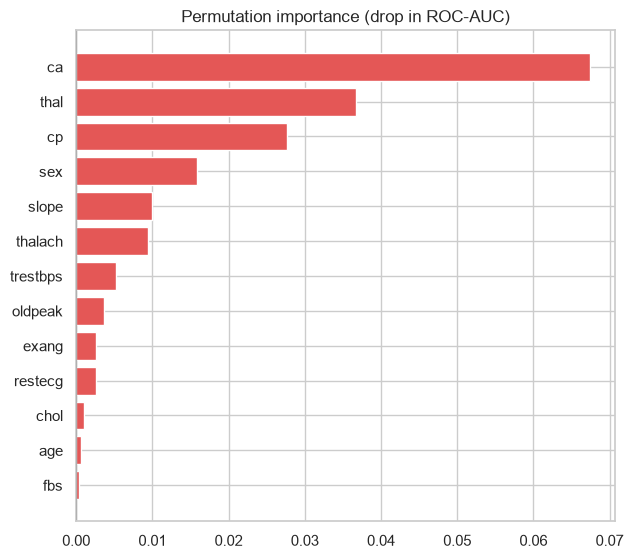

In [39]:
importance = evaluation.permutation_table(final_pipe, X_train, y_train)
plots.importance(importance, "Permutation importance (drop in ROC-AUC)");
print("Permutation importance:", importance.round(3).to_dict())
display(evaluation.coefficients(final_pipe).round(3).head(10).to_frame("coefficient"))

**Insight:** the model leans most on `ca` (shuffling it costs 0.067 ROC-AUC), then `thal` (0.037), chest-pain type (0.028) and sex (0.016), the same signals the EDA found strongest. Cholesterol, age and fasting blood sugar contribute almost nothing on their own (0.001, 0.001 and 0.0). The coefficients point the clinically expected way: more vessels (+0.859 per SD), male sex (+0.767), asymptomatic chest pain (+0.708) and a reversible thallium defect (+0.645) raise risk, while a normal thallium scan (−0.585) and a higher maximum heart rate (−0.342 per SD) lower it.

## 15. Limitations, impact and next steps

### 15.1 Limitations
* **Late-stage features (T15).** `ca` (vessels seen on fluoroscopy) and `thal` (thallium scan) are the model's strongest inputs and come late in the work-up; `ca` is close to how the diagnosis itself is made. The **10-feature model** is the main pre-angiography demo (Section 13): ROC-AUC 0.844 in Cleveland and 0.877 at a second hospital. `slope` is excluded for data completeness. Neither model is for first-contact screening.
* **Spectrum and selection bias (T16).** These are patients already referred for angiography at one hospital in the 1980s. Disease is far more common here than in the general population, and chest-pain patterns reflect who was referred (Section 5.2).
* **Small sample.** 303 patients, 61 in the test set. Test-set confidence intervals are wide, and the cross-validated estimate is the more stable one.
* **Under-served subgroup.** Out-of-fold recall is lower for women than for men (Section 12.2). The groups are small, but the gap points the same way as the missed-diagnosis literature.
* **Calibration (T17).** Logistic regression was already well calibrated, so we checked it (Brier score and calibration curve) rather than adding a calibration step; a new hospital would need re-calibration.

### 15.2 Clinical and operational impact

**Purpose:** collect, in one place, the numbers that show what the model changes for patients and for the angiography service. Every figure is recomputed from the results above.

In [40]:
low_row, default_row = compare.iloc[0], compare.iloc[1]
first_40 = gain.loc[gain["slots"] == 0.4, "model"].iloc[0]
dca_at = dca.set_index("threshold").loc[0.3]
COMPLICATIONS_PER_10000 = 8.2                               # major complications of diagnostic catheterisation (Al-Hijji 2019)
by_sex_recall = evaluation.subgroup_recall(X_train["sex"].map(cfg.LABELS["sex"]), y_train, oof, thresholds["low"])["recall"]
impact = {
    "Sick patients missed per 100 (chosen cut-off vs default 0.5)": f"{low_row['missed_per_100']:.1f} vs {default_row['missed_per_100']:.1f}",
    "Disease rate in the High tier vs all referred patients": f"{tiers.loc['High', 'disease rate %']:.1f}% vs {100 * y_train.mean():.1f}%",
    "Simulated disease in first 40% of slots (risk order vs proportional benchmark)": f"{first_40:.1%} vs 40.0%",
    "Per 1,000 referred: sick patients in High / left in Low": f"{per_1000.loc['High', 'disease']:.0f} / {per_1000.loc['Low', 'disease']:.0f}",
    "Net benefit at a 0.3 risk threshold (model vs angiography for all)": f"{dca_at['model']:.3f} vs {dca_at['treat_all']:.3f}",
    "Healthy patients spared a priority angiogram (Low tier, per 1,000 referred)": f"{per_1000.loc['Low', 'no disease']:.0f}",
    "Major complications avoided by that (8.2 per 10,000 procedures)": f"{per_1000.loc['Low', 'no disease'] * COMPLICATIONS_PER_10000 / 10000:.1f}",
    "Sick patients left in the Low tier (per 1,000 referred)": f"{per_1000.loc['Low', 'disease']:.1f}",
    "Out-of-fold recall for women vs men": f"{by_sex_recall['female']:.3f} vs {by_sex_recall['male']:.3f}",
    "Sick test patients flagged (locked test set)": f"{caught} of {sick}",
}
for key, value in impact.items():
    print(f"{key:<78}{value}")

Sick patients missed per 100 (chosen cut-off vs default 0.5)                  4.5 vs 9.9
Disease rate in the High tier vs all referred patients                        85.3% vs 45.9%
Simulated disease in first 40% of slots (risk order vs proportional benchmark)76.6% vs 40.0%
Per 1,000 referred: sick patients in High / left in Low                       360 / 46
Net benefit at a 0.3 risk threshold (model vs angiography for all)            0.340 vs 0.227
Healthy patients spared a priority angiogram (Low tier, per 1,000 referred)   368
Major complications avoided by that (8.2 per 10,000 procedures)               0.3
Sick patients left in the Low tier (per 1,000 referred)                       45.5
Out-of-fold recall for women vs men                                           0.778 vs 0.925
Sick test patients flagged (locked test set)                                  28 of 28


**Insight:** the retrospective model's simulated benefit is earlier use of slots, and its price is a material group of missed patients in Low. **Benefit:** it halves the sick patients missed at the default cut-off (4.5 against 9.9 per 100) and concentrates disease where the priority slots go (85.3% in the High tier against 45.9% overall), so 76.6% of sick patients would be in the first 40% of slots under simulated risk ordering versus a 40.0% proportional benchmark. About 368 healthy patients per 1,000 would fall outside the priority tier. Avoided procedures and complications were not observed. **Price:** about 45.5 sick patients per 1,000 remain in the Low tier, which is why that tier requires clinician review and a documented safety-net plan, and recall is lower for women than for men (0.778 against 0.925), a gap to monitor. Acting on the model still beats sending everyone to angiography (net benefit 0.340 against 0.227 at a 0.3 risk threshold), and on the locked test set 28 of 28 sick patients were flagged.

**Purpose:** illustrate a payment scenario, not measured cost savings. Per 1,000 referred patients, compare sending everyone to angiography with sending only the High and Medium tiers (the Low tier receives clinician review and a safety-net plan, and is assumed not to receive angiography in this scenario). Counting every Medium-tier patient as an angiogram is deliberately conservative: their recommended action is a cardiology review, not automatic angiography. Prices are the 2026 US Medicare national payments from Section 0: OPPS is the hospital-outpatient rate, ASC the ambulatory-surgical-centre rate; the physician's fee is left out, so both strategies are under-costed by the same amount per procedure.

In [41]:
# CMS CY 2026 OPPS/ASC final rule (CMS-1834-FC): national unadjusted Medicare payment for CPT 93458 (APC 5191)
ANGIOGRAM_PRICE_USD = {"OPPS": 3312, "ASC": 1708}
print("Medicare payment per diagnostic angiogram, calendar year 2026: "
      + ", ".join(f"{k} ${v:,}" for k, v in ANGIOGRAM_PRICE_USD.items()))

strategies = {
    "angiography for everyone": per_1000.loc[["Total"], ["patients", "disease", "no disease"]].sum(),
    "High + Medium tiers only": per_1000.loc[["High", "Medium"], ["patients", "disease", "no disease"]].sum(),
}
cost = pd.DataFrame({name: {"angiograms": s["patients"], "sick patients found": s["disease"],
                            "angiograms with no disease": s["no disease"],
                            "sick patients deferred to follow-up": per_1000.loc["Total", "disease"] - s["disease"]}
                     for name, s in strategies.items()}).T
for setting, price in ANGIOGRAM_PRICE_USD.items():
    cost[f"cost ($, {setting})"] = cost["angiograms"] * price
    cost[f"cost per sick patient found ($, {setting})"] = cost[f"cost ($, {setting})"] / cost["sick patients found"]
display(cost.T.apply(lambda row: row.map(("{:,.0f}" if "$" in row.name else "{:,.1f}").format), axis=1))

saved = cost.iloc[0] - cost.iloc[1]
for setting in ANGIOGRAM_PRICE_USD:
    print(f"Simulated payment difference per 1,000 referred ({setting}): ${saved[f'cost ($, {setting})']:,.0f} "
          f"for {saved['angiograms']:.1f} fewer angiograms")

Medicare payment per diagnostic angiogram, calendar year 2026: OPPS $3,312, ASC $1,708


,angiography for everyone,High + Medium tiers only
angiograms,"1,000.0",586.8
sick patients found,458.7,413.2
angiograms with no disease,541.3,173.6
sick patients deferred to follow-up,0.0,45.5
"cost ($, OPPS)","3,312,000","1,943,482"
"cost per sick patient found ($, OPPS)","7,220","4,703"
"cost ($, ASC)","1,708,000","1,002,254"
"cost per sick patient found ($, ASC)","3,724","2,426"


Simulated payment difference per 1,000 referred (OPPS): $1,368,518 for 413.2 fewer angiograms
Simulated payment difference per 1,000 referred (ASC): $705,746 for 413.2 fewer angiograms


**Insight:** withholding angiography from Low reduces simulated Medicare payments per sick patient found. Per 1,000 referred patients, sending everyone to angiography costs $3,312,000 at the 2026 hospital-outpatient (OPPS) rate, and 541.3 of those angiograms find no obstructive disease. Sending only the High and Medium tiers takes 586.8 angiograms and costs $1,943,482, a simulated payment difference of $1,368,518 (or $705,746 at the ASC rate), and the cost per sick patient found falls from $7,220 to $4,703. The price is the one shown above: 45.5 sick patients per 1,000 would not receive angiography under this scenario despite having disease. These are Medicare payments, not hospital costs; they leave out the physician's fee and they are American. A Thai hospital would substitute its own price, but actual procedure use, outcomes and savings need prospective measurement. These retrospective counts do not describe the reduced-input demo model.

### 15.3 Next steps

**Improving accuracy.** Each lever comes with the evidence that motivates it.
1. **More patients.** The learning curve (Section 9.4) was still rising at the full training set: pool the other UCI hospitals (Hungary, Switzerland, Long Beach VA) and modern records, with missing-value indicators for `ca`, `thal` and `slope`, which other hospitals rarely recorded.
2. **New information for the patients every model misses.** Six sick patients were missed by all four tuned models (Section 9.2), so another algorithm will not catch them; new inputs might (for example troponin, symptom duration, a coronary calcium score or the full stress-test trace).
3. **Bayesian search for the tree models.** A 100-setting search left logistic regression unchanged and added only 0.003 to XGBoost (Section 9.6), and dropping features gave no reliable gain (Section 9.5). The remaining check is Bayesian optimisation (for example Optuna) for XGBoost, scored by nested cross-validation (Section 9.3), repeated once more patients are pooled, because feature selection on 242 patients is noisy.
4. **Combine model families.** A stacked logistic regression + XGBoost, or XGBoost with monotonic constraints (risk may only rise with more diseased vessels or more ST depression), may add accuracy while staying clinically sensible. Adopt it only if it beats the shipped model at the recall-0.90 operating point (Section 9.2).
5. **Cost-weighted cut-offs.** Set the low cut-off from explicit, clinician-agreed costs of a missed patient versus an unnecessary angiogram instead of a fixed 90% recall target.
6. **Close the sex gap.** Out-of-fold recall was lower for women than for men (Section 12.2): collect more sick women, review their missed cases, and re-check subgroup recall after every change.

**Path to deployment.**
1. **Prospective silent pilot.** Run the model alongside clinicians without acting on it, and compare its tiers with real outcomes.
2. **Re-calibrate per hospital** and monitor drift in inputs and outcomes after deployment.
3. **Path to production** (beyond this proof of concept): electronic-record integration, a model service with a typed input contract (our `data.validate`), and monitoring.

### 15.4 How each trap from the original notebook was handled

| Trap | Problem in the original notebook | Where it is fixed |
|---|---|---|
| T1 | Kaggle labels inverted (`target = 1` meant no disease) | Section 3.2: proved row by row; UCI file used |
| T2 | Category codes re-mapped in the Kaggle copy | Section 3.2: recode table; official UCI dictionary (3.1) |
| T3 | Missing values hidden as fake codes (`ca = 4`, `thal = 0`) | Sections 3.2, 4.1: read as missing, imputed inside the pipeline |
| T4 | Duplicate patient (Kaggle dropped one sick patient, copied a healthy one) | Sections 3.2, 4.2: UCI has none; `deduplicate()` before splitting |
| T5 | KNN tuned on the test set | Section 9: all tuning inside cross-validation; test set used once (Section 11) |
| T6 | Tuned settings re-typed wrongly (`C = 4.89` instead of the best) | Section 9: the search's own best model is used directly |
| T7 | "Cross-validation" that included the test set | Section 6: CV on the training set only |
| T8 | No scaling (convergence warning, weak KNN) | Section 4.5 and the pipeline: standardisation inside each fold |
| T9 | Nominal codes treated as numbers | Sections 3.1, 4.5: one-hot encoding |
| T10 | Importance read from raw, unscaled coefficients | Section 14: permutation importance and standardised coefficients |
| T11 | Confusion-matrix axes mislabelled | Section 11: rows = true status, columns = model's call, labelled in words |
| T12 | Broken chart legend | Section 5: every chart labels classes explicitly |
| T13 | No random seeds on models | Section 2 and `models.py`: one seed everywhere; outputs identical across runs |
| T14 | 95%-accuracy goal | Sections 1 and 4.4: recall-first target; accuracy shown to be misleading |
| T15 | Late-stage imaging features | Sections 1, 5.5, 15.1: scope limited to post-work-up prioritisation |
| T16 | Referral-population bias | Sections 3, 12.2, 15.1: stated, and recall checked by subgroup |
| T17 | Uncalibrated "risk %" | Sections 9.1, 11: Brier score, calibration check and curve |
| T18 | Typos, empty cells, no environment file | Whole notebook; pinned `requirements.txt`; automated notebook check |

### 15.5 Model card

**Purpose:** summarise the shipped model in one place, with every number read from the results above.

In [42]:
model_card = {
    "Model": f"Logistic regression (C = {final_pipe.named_steps['model'].C:.3f}) on 13 UCI features",
    "Intended use": "Retrospective comparison only; ca availability before angiography is unverified",
    "Not for": "First-contact screening, the general population, or deciding without a clinician",
    "Training data": f"UCI Cleveland, {len(X_train)} patients (test set {len(X_test)} held out)",
    "Cut-offs": f"low {thresholds['low']:.3f} (recall target {cfg.RECALL_TARGET:.0%}), high {thresholds['high']:.3f}",
    "Cross-validated ROC-AUC": f"{tuned.loc[selected, 'roc_auc_mean']:.3f} ± {tuned.loc[selected, 'roc_auc_sd']:.3f}",
    "Test ROC-AUC (95% CI)": f"{test_ci.loc['roc_auc', 'point']:.3f} ({test_ci.loc['roc_auc', 'lo']:.3f} to {test_ci.loc['roc_auc', 'hi']:.3f})",
    "Test recall (exact 95% CI)": f"{caught}/{sick} ({recall_lo:.3f} to {recall_hi:.3f})",
    "Test specificity (95% CI)": f"{test_ci.loc['specificity', 'point']:.3f} ({test_ci.loc['specificity', 'lo']:.3f} to {test_ci.loc['specificity', 'hi']:.3f})",
    "Known gaps": "Lower recall for women (Section 12.2); single 1980s referral cohort; late-stage features",
}
for key, value in model_card.items():
    print(f"{key:<28}{value}")

Model                       Logistic regression (C = 0.216) on 13 UCI features
Intended use                Retrospective comparison only; ca availability before angiography is unverified
Not for                     First-contact screening, the general population, or deciding without a clinician
Training data               UCI Cleveland, 242 patients (test set 61 held out)
Cut-offs                    low 0.287 (recall target 90%), high 0.509
Cross-validated ROC-AUC     0.900 ± 0.035
Test ROC-AUC (95% CI)       0.961 (0.902 to 0.998)
Test recall (exact 95% CI)  28/28 (0.877 to 1.000)
Test specificity (95% CI)   0.667 (0.500 to 0.829)
Known gaps                  Lower recall for women (Section 12.2); single 1980s referral cohort; late-stage features


## 16. Save the model for the demo app

The app loads one file containing everything it needs: the 10-feature main model and the retrospective comparison, each with its own cut-offs and explanation baseline, plus four demo presets, headline metrics and library versions. The file is loaded only by this project's own code; never load a model file from an untrusted source, because unpickling can run code.

**Purpose:** pick the demo presets, save the artifact and a JSON copy of the metrics, and prove the saved file reproduces the notebook's predictions.

In [43]:
import json

import joblib

def preset(description, patient):
    risk = model10.predict_proba(patient)[0, 1]
    risk_full = final_pipe.predict_proba(patient)[0, 1]
    return {"description": description, "patient": patient.iloc[0][cfg.FEATURES].to_dict(),
            "expected_tier": triage.triage(risk, th10)["tier"], "risk": round(float(risk), 4),
            "risk_full": round(float(risk_full), 4)}

complete = X_test.dropna()                                     # presets need every field filled in for the app form
p_complete = model10.predict_proba(complete)[:, 1]
missed10 = X_train.loc[(y_train == 1) & (oof10 < th10["low"])]
missed10 = missed10.iloc[[int(np.argmin(model10.predict_proba(missed10)[:, 1]))]]
borderline = complete.iloc[[int(np.where(p_complete >= th10["low"])[0][np.argmin(p_complete[p_complete >= th10["low"]])])]]
presets = {
    "Clear high risk": preset("Test patient with the highest risk", complete.iloc[[int(np.argmax(p_complete))]]),
    "Clear low risk": preset("Test patient with the lowest risk", complete.iloc[[int(np.argmin(p_complete))]]),
    "Borderline": preset("Test patient just above the low cut-off", borderline),
    "Missed by the model": preset("Sick training patient placed Low by the reduced-input model out-of-fold", missed10),
}

metrics = {
    "selected_model": selected, "C": float(final_pipe.named_steps["model"].C), "use_domain_features": bool(USE_FE),
    "thresholds": {k: round(v, 4) for k, v in thresholds.items()},
    "cv_roc_auc": {"mean": round(float(tuned.loc[selected, "roc_auc_mean"]), 4), "sd": round(float(tuned.loc[selected, "roc_auc_sd"]), 4)},
    "test": {m: {k: round(float(v), 4) for k, v in row.items()} for m, row in test_ci.iterrows()},
    "test_recall_exact_ci": [round(recall_lo, 4), round(recall_hi, 4)],
    "no_imaging_cv_roc_auc": round(float(cv10["roc_auc"].mean()), 4),
    "decision_cv": {"recall": round(float(decision_rates["recall"]), 4),
                    "specificity": round(float(decision_rates["specificity"]), 4),
                    "high_ppv": round(float(decision_rates["high_ppv"]), 4)},
    "hungary_roc_auc_10_features": round(float(evaluation.bootstrap_ci(hungary[cfg.TARGET], p_hun, th10["low"]).loc["roc_auc", "point"]), 4),
    "hungary_recall_10_features": round(float((p_hun[hungary[cfg.TARGET].to_numpy() == 1] >= th10["low"]).mean()), 4),
}
artifact = {
    "pipeline": final_pipe, "thresholds": thresholds, "baseline": base, "features": cfg.FEATURES,
    "metrics": metrics, "presets": presets,
    "no_imaging": {"pipeline": model10, "thresholds": th10, "dropped": DROP,
                   "baseline": triage.baseline(model10, X_train)},
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
}
cfg.ARTIFACTS.mkdir(exist_ok=True)
joblib.dump(artifact, cfg.MODEL_PATH)
(cfg.ARTIFACTS / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

reloaded = joblib.load(cfg.MODEL_PATH)                         # our own file, written one line above
assert np.allclose(reloaded["pipeline"].predict_proba(X_test)[:, 1], p_test)
assert np.allclose(reloaded["no_imaging"]["pipeline"].predict_proba(X_test)[:, 1], model10.predict_proba(X_test)[:, 1])
print(f"Saved {cfg.MODEL_PATH.name} and metrics.json; reloaded pipeline reproduces all {len(X_test)} test predictions")
for name, pr in presets.items():
    print(f"  {name:<20} main risk {pr['risk']:.3f} -> {pr['expected_tier']}; retrospective risk {pr['risk_full']:.3f}")

Saved heart_disease_pipeline.joblib and metrics.json; reloaded pipeline reproduces all 61 test predictions
  Clear high risk      main risk 0.975 -> High; retrospective risk 0.964
  Clear low risk       main risk 0.021 -> Low; retrospective risk 0.059
  Borderline           main risk 0.303 -> Medium; retrospective risk 0.132
  Missed by the model  main risk 0.055 -> Low; retrospective risk 0.229


The saved file contains both models. The app uses the reduced-input model for its main score and presents the 13-feature model only as a retrospective comparison. Presets are selected by reduced-input predictions.
